# Combined Time Series Analysis Notebook

This notebook combines three time series analysis approaches:
1. Machine Learning Methods
2. SARIMA with Box-Cox Transformation
3. Unobserved Components Model (UCM) with Box-Cox Transformation

---
## Part 1: Time Series Machine Learning
---

In [1]:
# =============================================================================
# PART 1: IMPORTS AND DATA PREPARATION
# =============================================================================

# Core libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time series
import pmdarima as pm
from pmdarima.preprocessing import FourierFeaturizer
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

# Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

In [2]:
# =============================================================================
# ML MODELS - PART 1: SETUP AND FEATURE ENGINEERING
# =============================================================================

# Core libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Time series CV
from sklearn.model_selection import TimeSeriesSplit

# Holidays
import holidays

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

print("=" * 80)
print("MACHINE LEARNING MODELS: LightGBM & XGBoost")
print("=" * 80)
print("\nKey Strategy: Feature Engineering for Time Series")
print("  - Temporal features (hour, day, month)")
print("  - Lag features (past values)")
print("  - Rolling statistics (moving averages)")
print("  - Cyclical encoding (sin/cos transformations)")
print("  - Holiday indicators")
print("=" * 80)

MACHINE LEARNING MODELS: LightGBM & XGBoost

Key Strategy: Feature Engineering for Time Series
  - Temporal features (hour, day, month)
  - Lag features (past values)
  - Rolling statistics (moving averages)
  - Cyclical encoding (sin/cos transformations)
  - Holiday indicators


In [3]:
# =============================================================================
# ML MODELS - PART 2: FEATURE ENGINEERING FUNCTION
# =============================================================================

def create_time_features(df, target_col='value'):
    """
    Create comprehensive time series features from datetime index.
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with datetime index and target column
    target_col : str
        Name of the target column
        
    Returns:
    --------
    DataFrame with all features
    """
    df = df.copy()
    
    # Ensure datetime index
    if not isinstance(df.index, pd.DatetimeIndex):
        df.index = pd.to_datetime(df.index)
    
    # =========================
    # BASIC TIME FEATURES
    # =========================
    df['hour'] = df.index.hour
    df['day_of_week'] = df.index.dayofweek  # 0=Monday, 6=Sunday
    df['day_of_month'] = df.index.day
    df['day_of_year'] = df.index.dayofyear
    df['week_of_year'] = df.index.isocalendar().week
    df['month'] = df.index.month
    df['quarter'] = df.index.quarter
    df['year'] = df.index.year
    
    # =========================
    # BINARY FLAGS
    # =========================
    df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)
    df['is_month_start'] = df.index.is_month_start.astype(int)
    df['is_month_end'] = df.index.is_month_end.astype(int)
    df['is_quarter_start'] = df.index.is_quarter_start.astype(int)
    df['is_quarter_end'] = df.index.is_quarter_end.astype(int)
    
    # Business hours (9am-5pm weekdays)
    df['is_business_hours'] = (
        (df['hour'] >= 9) & (df['hour'] <= 17) & (df['day_of_week'] < 5)
    ).astype(int)
    
    # Night hours (10pm-6am)
    df['is_night'] = ((df['hour'] >= 22) | (df['hour'] <= 6)).astype(int)
    
    # =========================
    # CYCLICAL ENCODING
    # =========================
    # Hour (24-hour cycle)
    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
    
    # Day of week (7-day cycle)
    df['dow_sin'] = np.sin(2 * np.pi * df['day_of_week'] / 7)
    df['dow_cos'] = np.cos(2 * np.pi * df['day_of_week'] / 7)
    
    # Month (12-month cycle)
    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
    
    # Day of year (365-day cycle)
    df['doy_sin'] = np.sin(2 * np.pi * df['day_of_year'] / 365.25)
    df['doy_cos'] = np.cos(2 * np.pi * df['day_of_year'] / 365.25)
    
    # =========================
    # AUSTRALIAN HOLIDAYS
    # =========================
    # Create Australian holiday calendar
    au_holidays = holidays.Australia(years=range(df.index.year.min(), df.index.year.max() + 1))
    
    df['is_holiday'] = pd.Series(df.index.date, index=df.index).isin(au_holidays.keys()).astype(int)
    
    # Days before/after holiday
    df['days_to_holiday'] = 0
    df['days_from_holiday'] = 0
    
    for i, date in enumerate(df.index.date):
        # Find nearest holiday
        future_holidays = [h for h in au_holidays.keys() if h > date]
        past_holidays = [h for h in au_holidays.keys() if h < date]
        
        if future_holidays:
            days_to = (min(future_holidays) - date).days
            df.loc[df.index[i], 'days_to_holiday'] = min(days_to, 30)  # Cap at 30
        
        if past_holidays:
            days_from = (date - max(past_holidays)).days
            df.loc[df.index[i], 'days_from_holiday'] = min(days_from, 30)  # Cap at 30
    
    # =========================
    # INTERACTION FEATURES
    # =========================
    df['hour_x_dow'] = df['hour'] * df['day_of_week']
    df['hour_x_is_weekend'] = df['hour'] * df['is_weekend']
    df['is_weekend_x_is_holiday'] = df['is_weekend'] * df['is_holiday']
    
    return df

def create_lag_features(df, target_col='value', lags=[1, 24, 48, 168, 336]):
    """
    Create lag features (past values).
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with target column
    target_col : str
        Name of target column
    lags : list
        List of lag periods
        
    Returns:
    --------
    DataFrame with lag features
    """
    df = df.copy()
    
    for lag in lags:
        df[f'lag_{lag}'] = df[target_col].shift(lag)
    
    return df


def create_rolling_features(df, target_col='value', windows=[24, 168]):
    """
    Create rolling window statistics.
    
    Parameters:
    -----------
    df : DataFrame
        DataFrame with target column
    target_col : str
        Name of target column
    windows : list
        List of window sizes
        
    Returns:
    --------
    DataFrame with rolling features
    """
    df = df.copy()
    
    for window in windows:
        # Rolling mean
        df[f'rolling_mean_{window}'] = df[target_col].shift(1).rolling(window=window).mean()
        
        # Rolling std
        df[f'rolling_std_{window}'] = df[target_col].shift(1).rolling(window=window).std()
        
        # Rolling min/max
        df[f'rolling_min_{window}'] = df[target_col].shift(1).rolling(window=window).min()
        df[f'rolling_max_{window}'] = df[target_col].shift(1).rolling(window=window).max()
        
        # Rolling median
        df[f'rolling_median_{window}'] = df[target_col].shift(1).rolling(window=window).median()
    
    return df


def create_all_features(df, target_col='value'):
    """
    Create all features for ML models.
    """
    print("Creating features...")
    print("  - Time features...", end=' ')
    df = create_time_features(df, target_col)
    print("✓")
    
    print("  - Lag features...", end=' ')
    df = create_lag_features(df, target_col, lags=[1, 2, 24, 48, 168, 336])
    print("✓")
    
    print("  - Rolling features...", end=' ')
    df = create_rolling_features(df, target_col, windows=[24, 168])
    print("✓")
    
    # Drop rows with NaN (from lags/rolling windows)
    initial_len = len(df)
    df = df.dropna()
    dropped = initial_len - len(df)
    
    print(f"\nFeature engineering complete!")
    print(f"  Total features created: {len(df.columns) - 1}")  # -1 for target
    print(f"  Rows dropped (due to NaN): {dropped}")
    print(f"  Remaining rows: {len(df)}")
    
    return df

# Test the function (you'll apply this to your data next)
print("\nFeature engineering functions ready!")


Feature engineering functions ready!


In [4]:
# =============================================================================
# LOAD DATA
# =============================================================================

# Load dataset 
df = pd.read_csv("C:\\Users\\kekko\\Downloads\\student_dataset.csv")
df = df.rename(columns={'time': 'date'})

# Ensure 'date' is datetime and set as index
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')
df = df.sort_index()

print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"First few rows:\n{df.head()}")

Dataset shape: (42767, 1)
Date range: 2015-04-15 00:00:01 to 2020-02-29 22:00:01
First few rows:
                     value
date                      
2015-04-15 00:00:01   13.0
2015-04-15 01:00:01    2.0
2015-04-15 02:00:01    5.0
2015-04-15 03:00:01    3.0
2015-04-15 04:00:01    8.0


In [5]:
# =============================================================================
# Reduce dataset size for computational efficiency
# =============================================================================

# Percentage of data to KEEP (from the end of the dataset)
# Change this value to adjust the reduction (e.g. 0.5 = 50%, 0.2 = 20%)
KEEP_PERCENTAGE = 0.4

cutoff_index = int(len(df) * (1 - KEEP_PERCENTAGE))
df = df.iloc[cutoff_index:]

print(f"Kept last {KEEP_PERCENTAGE*100}% of data")
print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"First few rows:\n{df.head()}")

Kept last 40.0% of data
Dataset shape: (17107, 1)
Date range: 2018-03-19 04:00:01 to 2020-02-29 22:00:01
First few rows:
                     value
date                      
2018-03-19 04:00:01    2.0
2018-03-19 05:00:01   39.0
2018-03-19 06:00:01   99.0
2018-03-19 07:00:01  294.0
2018-03-19 08:00:01  306.0


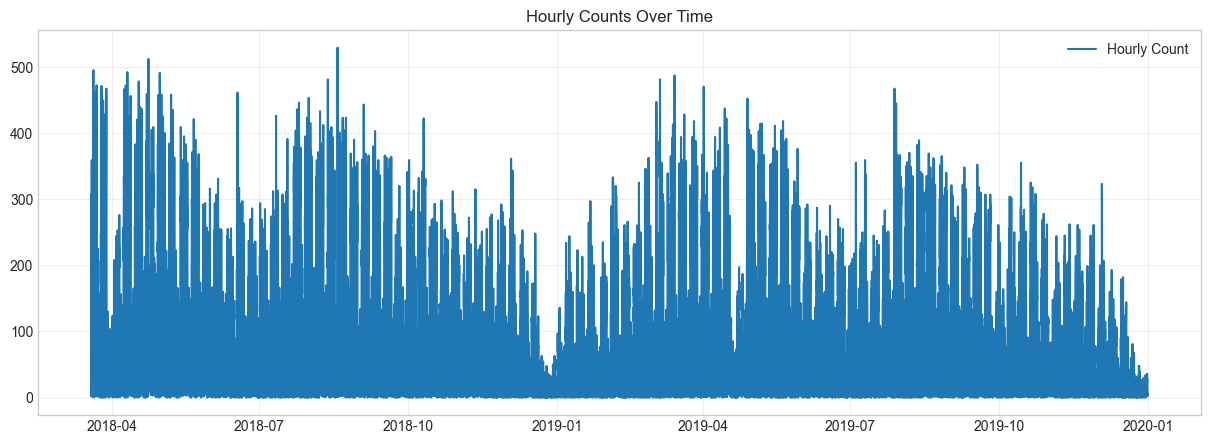

In [6]:
# Plot the dataset
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'], label='Hourly Count', color='#1f77b4')
plt.title('Hourly Counts Over Time')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [7]:
# =============================================================================
# ML MODELS - PART 3: PREPARE DATA WITH FEATURES
# =============================================================================

# Use the data with values (same as before)
df_with_values = df[df['value'].notna()].copy()

print(f"Original data: {len(df_with_values)} observations")
print(f"Date range: {df_with_values.index.min()} to {df_with_values.index.max()}")

# Create all features
df_features = create_all_features(df_with_values, target_col='value')

print(f"\nFeatures created:")
print(f"  Shape: {df_features.shape}")
print(f"  Columns: {df_features.columns.tolist()}")

Original data: 15668 observations
Date range: 2018-03-19 04:00:01 to 2019-12-31 23:00:01
Creating features...
  - Time features... ✓
  - Lag features... ✓
  - Rolling features... ✓

Feature engineering complete!
  Total features created: 45
  Rows dropped (due to NaN): 336
  Remaining rows: 15332

Features created:
  Shape: (15332, 46)
  Columns: ['value', 'hour', 'day_of_week', 'day_of_month', 'day_of_year', 'week_of_year', 'month', 'quarter', 'year', 'is_weekend', 'is_month_start', 'is_month_end', 'is_quarter_start', 'is_quarter_end', 'is_business_hours', 'is_night', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'doy_sin', 'doy_cos', 'is_holiday', 'days_to_holiday', 'days_from_holiday', 'hour_x_dow', 'hour_x_is_weekend', 'is_weekend_x_is_holiday', 'lag_1', 'lag_2', 'lag_24', 'lag_48', 'lag_168', 'lag_336', 'rolling_mean_24', 'rolling_std_24', 'rolling_min_24', 'rolling_max_24', 'rolling_median_24', 'rolling_mean_168', 'rolling_std_168', 'rolling_min_168', 'r

In [8]:
FORECAST_HORIZON = 1440  # 60 days * 24 hours

# After feature engineering, we need to split
# The last 336 rows (due to lag_336) are already dropped

# Split indices
train_end_idx = len(df_features) - FORECAST_HORIZON
val_end_idx = len(df_features)

train_ml = df_features.iloc[:train_end_idx].copy()
validation_ml = df_features.iloc[train_end_idx:val_end_idx].copy()

print(f"\n{'='*80}")
print(f"ML DATA SPLIT")
print(f"{'='*80}")
print(f"Training set:   {len(train_ml):,} obs | {train_ml.index.min()} to {train_ml.index.max()}")
print(f"Validation set: {len(validation_ml):,} obs | {validation_ml.index.min()} to {validation_ml.index.max()}")
print(f"{'='*80}")

# Separate features and target
feature_cols = [col for col in df_features.columns if col != 'value']

X_train = train_ml[feature_cols]
y_train = train_ml['value']

X_val = validation_ml[feature_cols]
y_val = validation_ml['value']

print(f"\nFeature matrix shapes:")
print(f"  X_train: {X_train.shape}")
print(f"  X_val: {X_val.shape}")
print(f"\nNumber of features: {len(feature_cols)}")


ML DATA SPLIT
Training set:   13,892 obs | 2018-04-02 04:00:01 to 2019-11-01 23:00:01
Validation set: 1,440 obs | 2019-11-02 00:00:01 to 2019-12-31 23:00:01

Feature matrix shapes:
  X_train: (13892, 45)
  X_val: (1440, 45)

Number of features: 45



TRAINING LIGHTGBM MODEL

LightGBM Parameters:
  objective: regression
  metric: rmse
  boosting_type: gbdt
  num_leaves: 31
  learning_rate: 0.05
  feature_fraction: 0.8
  bagging_fraction: 0.8
  bagging_freq: 5
  max_depth: 7
  min_child_samples: 20
  reg_alpha: 0.1
  reg_lambda: 0.1
  verbose: -1
  random_state: 42

Training LightGBM...
Training until validation scores don't improve for 50 rounds
[100]	train's rmse: 20.9844	valid's rmse: 17.4778
[200]	train's rmse: 19.0388	valid's rmse: 17.1056
[300]	train's rmse: 17.4972	valid's rmse: 17.1101
Early stopping, best iteration is:
[265]	train's rmse: 18.0412	valid's rmse: 17.022

✓ LightGBM training complete!
  Best iteration: 265
  Best score: 17.0220

METRICS LIGHTGBM VALIDATION
RMSE:  17.02
MAE:   10.35
MAPE:  51152034040215840.00% (all data)
MAPE:  40.53% (excluding zeros)

Top 20 Most Important Features (LightGBM):
           feature   importance
             lag_1 6.340932e+08
           lag_168 2.489607e+08
           lag_336 3.

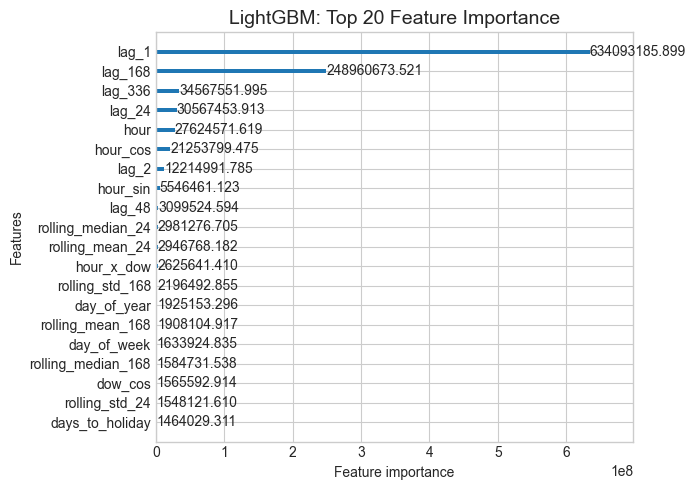

In [ ]:
# =============================================================================
# ML MODELS - PART 4: LIGHTGBM
# =============================================================================

print("\n" + "=" * 80)
print("TRAINING LIGHTGBM MODEL")
print("=" * 80)

# LightGBM parameters (tuned for time series)
lgb_params = {
    'objective': 'regression',
    'metric': 'rmse',
    'boosting_type': 'gbdt',
    'num_leaves': 31,
    'learning_rate': 0.05,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq': 5,
    'max_depth': 7,
    'min_child_samples': 20,
    'reg_alpha': 0.1,
    'reg_lambda': 0.1,
    'verbose': -1,
    'random_state': 42
}

print("\nLightGBM Parameters:")
for key, value in lgb_params.items():
    print(f"  {key}: {value}")

# Create datasets
lgb_train = lgb.Dataset(X_train, y_train)
lgb_val = lgb.Dataset(X_val, y_val, reference=lgb_train)

# Train model
print("\nTraining LightGBM...")
lgb_model = lgb.train(
    lgb_params,
    lgb_train,
    num_boost_round=1000,
    valid_sets=[lgb_train, lgb_val],
    valid_names=['train', 'valid'],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=100)
    ]
)

print(f"\n✓ LightGBM training complete!")
print(f"  Best iteration: {lgb_model.best_iteration}")
print(f"  Best score: {lgb_model.best_score['valid']['rmse']:.4f}")

# Make predictions on validation set
lgb_val_pred = lgb_model.predict(X_val, num_iteration=lgb_model.best_iteration)
lgb_val_pred = np.clip(lgb_val_pred, 0, None)  # Clip negative predictions

# Calculate metrics
def calculate_metrics(actual, predicted, name=""):
    """Calculate and print forecast metrics."""
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    mape = mean_absolute_percentage_error(actual, predicted) * 100
    
    # Handle MAPE for zero values
    mask = actual > 0
    mape_nonzero = mean_absolute_percentage_error(actual[mask], predicted[mask]) * 100
    
    print(f"\n{'='*50}")
    print(f"METRICS {name}")
    print(f"{'='*50}")
    print(f"RMSE:  {rmse:.2f}")
    print(f"MAE:   {mae:.2f}")
    print(f"MAPE:  {mape:.2f}% (all data)")
    print(f"MAPE:  {mape_nonzero:.2f}% (excluding zeros)")
    print(f"{'='*50}")
    
    return {'rmse': rmse, 'mae': mae, 'mape': mape, 'mape_nonzero': mape_nonzero}

lgb_metrics = calculate_metrics(y_val, lgb_val_pred, name="LIGHTGBM VALIDATION")

# Feature importance
print("\nTop 20 Most Important Features (LightGBM):")
feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': lgb_model.feature_importance(importance_type='gain')
}).sort_values('importance', ascending=False)

print(feature_importance.head(20).to_string(index=False))

# Plot feature importance
fig, ax = plt.subplots(figsize=(7, 5))
lgb.plot_importance(lgb_model, max_num_features=20, ax=ax, importance_type='gain')
plt.title('LightGBM: Top 20 Feature Importance', fontsize=14)
plt.tight_layout()
plt.show()


TRAINING XGBOOST MODEL

XGBoost Parameters:
  objective: reg:squarederror
  eval_metric: rmse
  booster: gbtree
  max_depth: 7
  learning_rate: 0.05
  subsample: 0.8
  colsample_bytree: 0.8
  min_child_weight: 3
  gamma: 0.1
  reg_alpha: 0.1
  reg_lambda: 1.0
  random_state: 42
  verbosity: 1

Training XGBoost...
[0]	train-rmse:93.08493	valid-rmse:68.62955
[100]	train-rmse:17.16405	valid-rmse:17.18858
[165]	train-rmse:15.04815	valid-rmse:17.18701

✓ XGBoost training complete!
  Best iteration: 115
  Best score: 17.1699

METRICS XGBOOST VALIDATION
RMSE:  17.17
MAE:   10.44
MAPE:  64847225378133376.00% (all data)
MAPE:  42.88% (excluding zeros)

Top 20 Most Important Features (XGBoost):
           feature    importance
             lag_1 448087.062500
           lag_168 215359.875000
          is_night 112296.210938
            lag_24  40754.507812
              hour  38141.871094
          hour_cos  36967.113281
           lag_336  28242.814453
             lag_2  22090.058594
       d

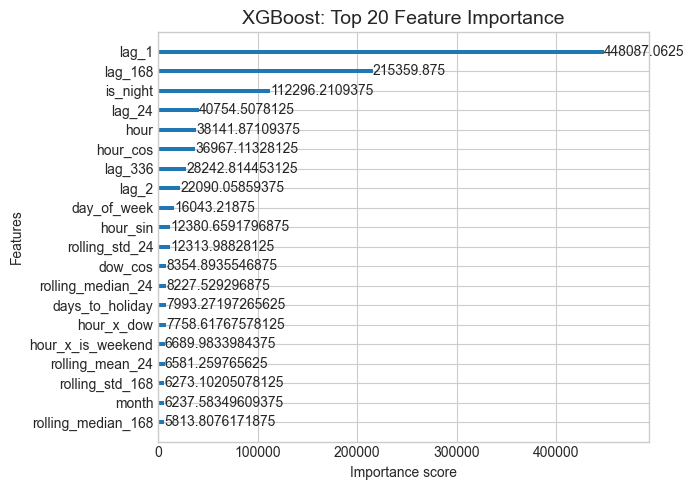

In [11]:
# =============================================================================
# ML MODELS - PART 5: XGBOOST
# =============================================================================

print("\n" + "=" * 80)
print("TRAINING XGBOOST MODEL")
print("=" * 80)

# XGBoost parameters (tuned for time series)
xgb_params = {
    'objective': 'reg:squarederror',
    'eval_metric': 'rmse',
    'booster': 'gbtree',
    'max_depth': 7,
    'learning_rate': 0.05,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'min_child_weight': 3,
    'gamma': 0.1,
    'reg_alpha': 0.1,
    'reg_lambda': 1.0,
    'random_state': 42,
    'verbosity': 1
}

print("\nXGBoost Parameters:")
for key, value in xgb_params.items():
    print(f"  {key}: {value}")

# Create DMatrix
dtrain = xgb.DMatrix(X_train, label=y_train)
dval = xgb.DMatrix(X_val, label=y_val)

# Train model
print("\nTraining XGBoost...")
evals = [(dtrain, 'train'), (dval, 'valid')]

xgb_model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=1000,
    evals=evals,
    early_stopping_rounds=50,
    verbose_eval=100
)

print(f"\n✓ XGBoost training complete!")
print(f"  Best iteration: {xgb_model.best_iteration}")
print(f"  Best score: {xgb_model.best_score:.4f}")

# Make predictions on validation set
xgb_val_pred = xgb_model.predict(dval, iteration_range=(0, xgb_model.best_iteration + 1))
xgb_val_pred = np.clip(xgb_val_pred, 0, None)  # Clip negative predictions

# Calculate metrics
xgb_metrics = calculate_metrics(y_val, xgb_val_pred, name="XGBOOST VALIDATION")

# Feature importance
print("\nTop 20 Most Important Features (XGBoost):")
xgb_importance = xgb_model.get_score(importance_type='gain')
xgb_importance_df = pd.DataFrame({
    'feature': list(xgb_importance.keys()),
    'importance': list(xgb_importance.values())
}).sort_values('importance', ascending=False)

print(xgb_importance_df.head(20).to_string(index=False))

# Plot feature importance
fig, ax = plt.subplots(figsize=(7, 5))
xgb.plot_importance(xgb_model, max_num_features=20, ax=ax, importance_type='gain')
plt.title('XGBoost: Top 20 Feature Importance', fontsize=14)
plt.tight_layout()
plt.show()


MODEL COMPARISON - VALIDATION RESULTS

   Model      RMSE       MAE  MAPE_nonzero
LightGBM 17.021692 10.348113     40.526874
 XGBoost 17.169888 10.436152     42.879650
     UCM 56.410000 38.810000    199.700000
  SARIMA 65.400000 51.210000    472.020000

🏆 BEST MODEL (by RMSE): LightGBM
   RMSE: 17.02
   MAE: 10.35


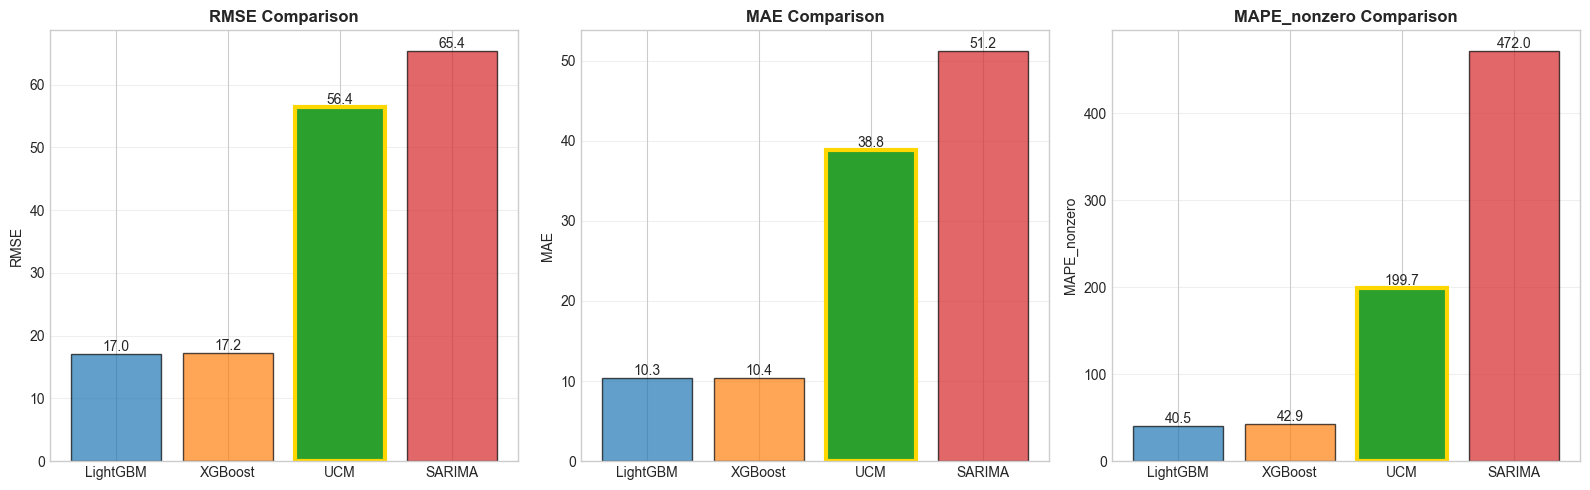

In [ ]:
# =============================================================================
# ML MODELS - PART 6: MODEL COMPARISON (VALIDATION)
# =============================================================================

print("\n" + "=" * 80)
print("MODEL COMPARISON - VALIDATION RESULTS")
print("=" * 80)

# Create comparison DataFrame
comparison_df = pd.DataFrame({
    'Model': ['SARIMA', 'UCM', 'LightGBM', 'XGBoost'],
    'RMSE': [65.40, 56.41, lgb_metrics['rmse'], xgb_metrics['rmse']],
    'MAE': [51.21, 38.81, lgb_metrics['mae'], xgb_metrics['mae']],
    'MAPE_nonzero': [472.02, 199.70, lgb_metrics['mape_nonzero'], xgb_metrics['mape_nonzero']]
})

# Sort by RMSE
comparison_df = comparison_df.sort_values('RMSE')

print("\n" + comparison_df.to_string(index=False))
print("=" * 80)

# Determine winner
best_model = comparison_df.iloc[0]['Model']
print(f"\n🏆 BEST MODEL (by RMSE): {best_model}")
print(f"   RMSE: {comparison_df.iloc[0]['RMSE']:.2f}")
print(f"   MAE: {comparison_df.iloc[0]['MAE']:.2f}")

# Visualize comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics_to_plot = ['RMSE', 'MAE', 'MAPE_nonzero']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx]
    bars = ax.bar(comparison_df['Model'], comparison_df[metric], color=colors, alpha=0.7, edgecolor='black')
    
    # Highlight best
    best_idx = comparison_df[metric].idxmin()
    bars[best_idx].set_alpha(1.0)
    bars[best_idx].set_edgecolor('gold')
    bars[best_idx].set_linewidth(3)
    
    ax.set_title(f'{metric} Comparison', fontsize=12, fontweight='bold')
    ax.set_ylabel(metric)
    ax.grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}',
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

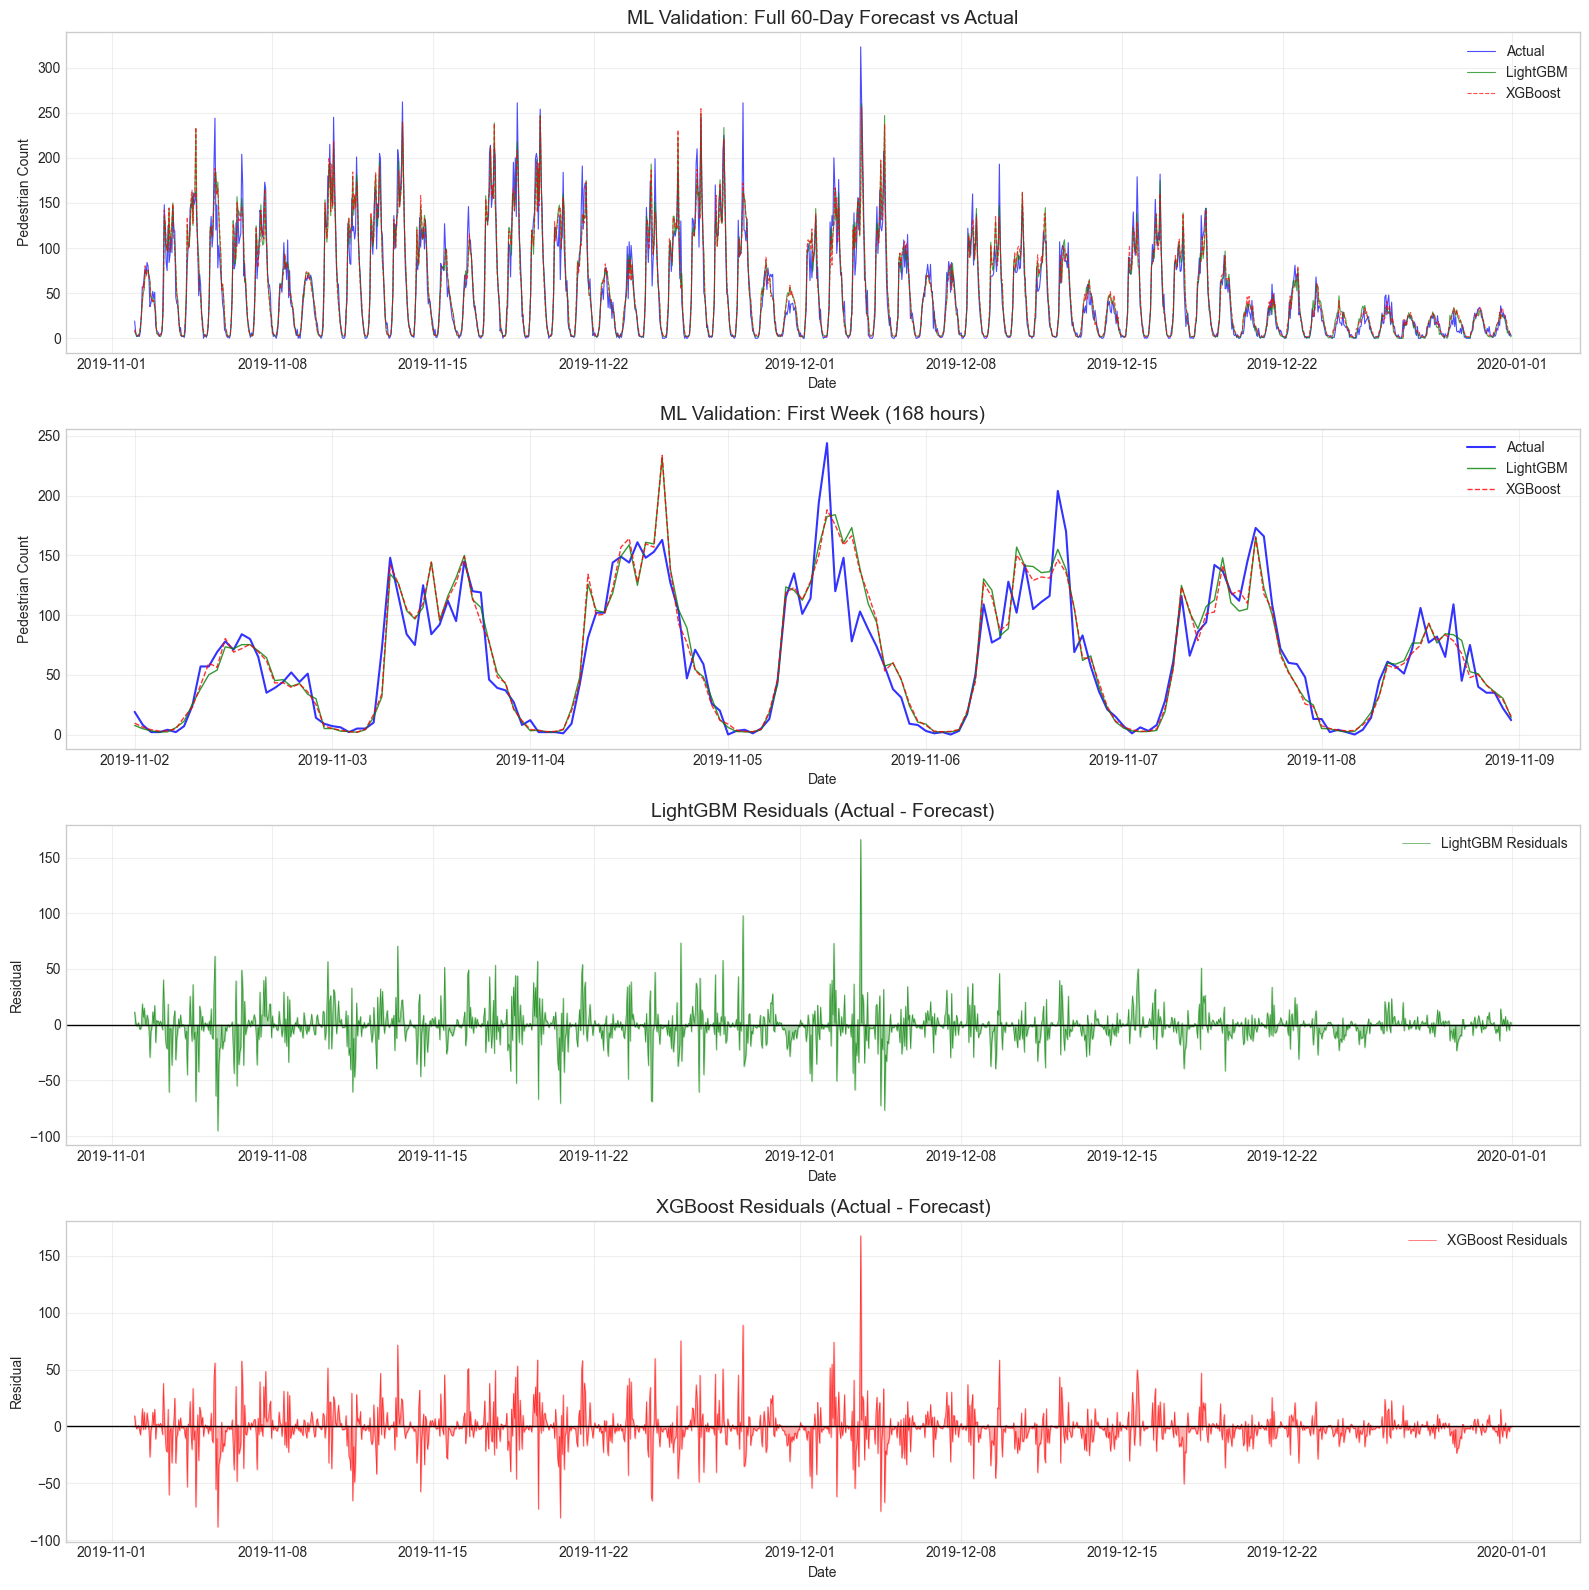

In [13]:
# =============================================================================
# ML MODELS - PART 7: VISUALIZATION OF VALIDATION FORECASTS
# =============================================================================

# Create validation forecast DataFrames
lgb_val_forecast_df = pd.DataFrame({
    'actual': y_val.values,
    'forecast': lgb_val_pred,
    'date': y_val.index
}).set_index('date')

xgb_val_forecast_df = pd.DataFrame({
    'actual': y_val.values,
    'forecast': xgb_val_pred,
    'date': y_val.index
}).set_index('date')

# Plot validation forecasts
fig, axes = plt.subplots(4, 1, figsize=(16, 16))

# Plot 1: Full 60-day validation period
ax1 = axes[0]
ax1.plot(y_val.index, y_val.values, label='Actual', alpha=0.7, linewidth=0.8, color='blue')
ax1.plot(lgb_val_forecast_df.index, lgb_val_forecast_df['forecast'], 
         label='LightGBM', alpha=0.7, linewidth=0.8, color='green')
ax1.plot(xgb_val_forecast_df.index, xgb_val_forecast_df['forecast'], 
         label='XGBoost', alpha=0.7, linewidth=0.8, color='red', linestyle='--')
ax1.set_title('ML Validation: Full 60-Day Forecast vs Actual', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Pedestrian Count')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: First week zoom
first_week = slice(0, 168)
ax2 = axes[1]
ax2.plot(y_val.index[first_week], y_val.values[first_week], 
         label='Actual', alpha=0.8, linewidth=1.5, color='blue')
ax2.plot(lgb_val_forecast_df.index[first_week], lgb_val_forecast_df['forecast'].values[first_week], 
         label='LightGBM', alpha=0.8, linewidth=1, color='green')
ax2.plot(xgb_val_forecast_df.index[first_week], xgb_val_forecast_df['forecast'].values[first_week], 
         label='XGBoost', alpha=0.8, linewidth=1, color='red', linestyle='--')
ax2.set_title('ML Validation: First Week (168 hours)', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Pedestrian Count')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: LightGBM Residuals
lgb_residuals = y_val.values - lgb_val_pred
ax3 = axes[2]
ax3.plot(y_val.index, lgb_residuals, alpha=0.7, linewidth=0.5, color='green', label='LightGBM Residuals')
ax3.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax3.fill_between(y_val.index, lgb_residuals, 0, alpha=0.3, color='green')
ax3.set_title('LightGBM Residuals (Actual - Forecast)', fontsize=14)
ax3.set_xlabel('Date')
ax3.set_ylabel('Residual')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot 4: XGBoost Residuals
xgb_residuals = y_val.values - xgb_val_pred
ax4 = axes[3]
ax4.plot(y_val.index, xgb_residuals, alpha=0.7, linewidth=0.5, color='red', label='XGBoost Residuals')
ax4.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax4.fill_between(y_val.index, xgb_residuals, 0, alpha=0.3, color='red')
ax4.set_title('XGBoost Residuals (Actual - Forecast)', fontsize=14)
ax4.set_xlabel('Date')
ax4.set_ylabel('Residual')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
# =============================================================================
# ML MODELS - PART 8: RETRAIN ON FULL DATA & FINAL FORECAST
# =============================================================================

print("\n" + "=" * 80)
print("RETRAINING ML MODELS ON FULL DATA")
print("=" * 80)

# Combine train and validation for final training
full_train_ml = pd.concat([train_ml, validation_ml])

X_full = full_train_ml[feature_cols]
y_full = full_train_ml['value']

print(f"\nFull training data: {len(X_full):,} observations")
print(f"Date range: {X_full.index.min()} to {X_full.index.max()}")

# =============================================================================
# RETRAIN LIGHTGBM
# =============================================================================

print("\n" + "-" * 80)
print("Retraining LightGBM on full data...")
print("-" * 80)

lgb_full_train = lgb.Dataset(X_full, y_full)

lgb_final_model = lgb.train(
    lgb_params,
    lgb_full_train,
    num_boost_round=lgb_model.best_iteration,  # Use best iteration from validation
)

print("✓ LightGBM retrained successfully")

# =============================================================================
# RETRAIN XGBOOST
# =============================================================================

print("\n" + "-" * 80)
print("Retraining XGBoost on full data...")
print("-" * 80)

dfull = xgb.DMatrix(X_full, label=y_full)

xgb_final_model = xgb.train(
    xgb_params,
    dfull,
    num_boost_round=xgb_model.best_iteration,  # Use best iteration from validation
    verbose_eval=False
)

print("✓ XGBoost retrained successfully")



RETRAINING ML MODELS ON FULL DATA

Full training data: 15,332 observations
Date range: 2018-04-02 04:00:01 to 2019-12-31 23:00:01

--------------------------------------------------------------------------------
Retraining LightGBM on full data...
--------------------------------------------------------------------------------
✓ LightGBM retrained successfully

--------------------------------------------------------------------------------
Retraining XGBoost on full data...
--------------------------------------------------------------------------------
✓ XGBoost retrained successfully


In [17]:
# =============================================================================
# PREPARE FORECAST FEATURES
# =============================================================================

print("\n" + "-" * 80)
print("Preparing features for forecast period...")
print("-" * 80)

# Create future dates
last_date = X_full.index.max()
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(hours=1),
    periods=FORECAST_HORIZON,
    freq='H'
)

print(f"Forecast period: {future_dates.min()} to {future_dates.max()}")

# Create a DataFrame with future dates
future_df = pd.DataFrame(index=future_dates)
future_df['value'] = np.nan  # Placeholder for target

# IMPORTANT: For forecasting, we need to iteratively predict
# because lag features depend on previous predictions

print("\nGenerating iterative forecasts (this may take a moment)...")

# Initialize with the last known values from training
historical_values = full_train_ml['value'].copy()

# Storage for predictions
lgb_forecast_list = []
xgb_forecast_list = []

for i, future_date in enumerate(future_dates):
    if (i + 1) % 240 == 0:  # Progress update every 10 days
        print(f"  Forecasting hour {i+1}/{FORECAST_HORIZON}...")
    
    # Create temporary df with historical + current future point
    temp_df = pd.DataFrame({'value': historical_values})
    temp_df = pd.concat([temp_df, pd.DataFrame({'value': [np.nan]}, index=[future_date])])
    
    # Create features for this single point
    temp_with_features = create_time_features(temp_df, target_col='value')
    temp_with_features = create_lag_features(temp_with_features, target_col='value', lags=[1, 2, 24, 48, 168, 336])
    temp_with_features = create_rolling_features(temp_with_features, target_col='value', windows=[24, 168])
    
    # Get the last row (our forecast point)
    forecast_features = temp_with_features.iloc[-1:][feature_cols]
    
    # Check if we have all features (no NaN)
    if forecast_features.isna().any().any():
        # If we have NaN, use the mean of recent predictions or last known value
        # This shouldn't happen if lags are properly set, but safety check
        lgb_pred = historical_values.iloc[-24:].mean()
        xgb_pred = historical_values.iloc[-24:].mean()
    else:
        # Make predictions
        lgb_pred = lgb_final_model.predict(forecast_features)[0]
        lgb_pred = max(0, lgb_pred)  # Clip to non-negative
        
        dforecast = xgb.DMatrix(forecast_features)
        xgb_pred = xgb_final_model.predict(dforecast)[0]
        xgb_pred = max(0, xgb_pred)  # Clip to non-negative
    
    # Store predictions
    lgb_forecast_list.append(lgb_pred)
    xgb_forecast_list.append(xgb_pred)
    
    # Update historical values with the average of both predictions for next iteration
    # (or you could use just one model - using average for robustness)
    avg_pred = (lgb_pred + xgb_pred) / 2
    historical_values = pd.concat([historical_values, pd.Series([avg_pred], index=[future_date])])

print("✓ Forecasts generated")

# Create forecast DataFrames
lgb_final_forecast_df = pd.DataFrame({
    'date': future_dates,
    'forecast': lgb_forecast_list
}).set_index('date')

xgb_final_forecast_df = pd.DataFrame({
    'date': future_dates,
    'forecast': xgb_forecast_list
}).set_index('date')

print("\nForecast Summary (LightGBM):")
print(lgb_final_forecast_df.describe())

print("\nForecast Summary (XGBoost):")
print(xgb_final_forecast_df.describe())


--------------------------------------------------------------------------------
Preparing features for forecast period...
--------------------------------------------------------------------------------
Forecast period: 2020-01-01 00:00:01 to 2020-02-29 23:00:01

Generating iterative forecasts (this may take a moment)...
  Forecasting hour 240/1440...
  Forecasting hour 480/1440...
  Forecasting hour 720/1440...
  Forecasting hour 960/1440...
  Forecasting hour 1200/1440...
  Forecasting hour 1440/1440...
✓ Forecasts generated

Forecast Summary (LightGBM):
          forecast
count  1440.000000
mean     37.393825
std      31.982399
min       1.461872
25%       5.055479
50%      32.630497
75%      62.979535
max     136.995139

Forecast Summary (XGBoost):
          forecast
count  1440.000000
mean     36.978958
std      30.582014
min       1.897028
25%       4.857888
50%      32.820501
75%      62.911346
max     121.505020


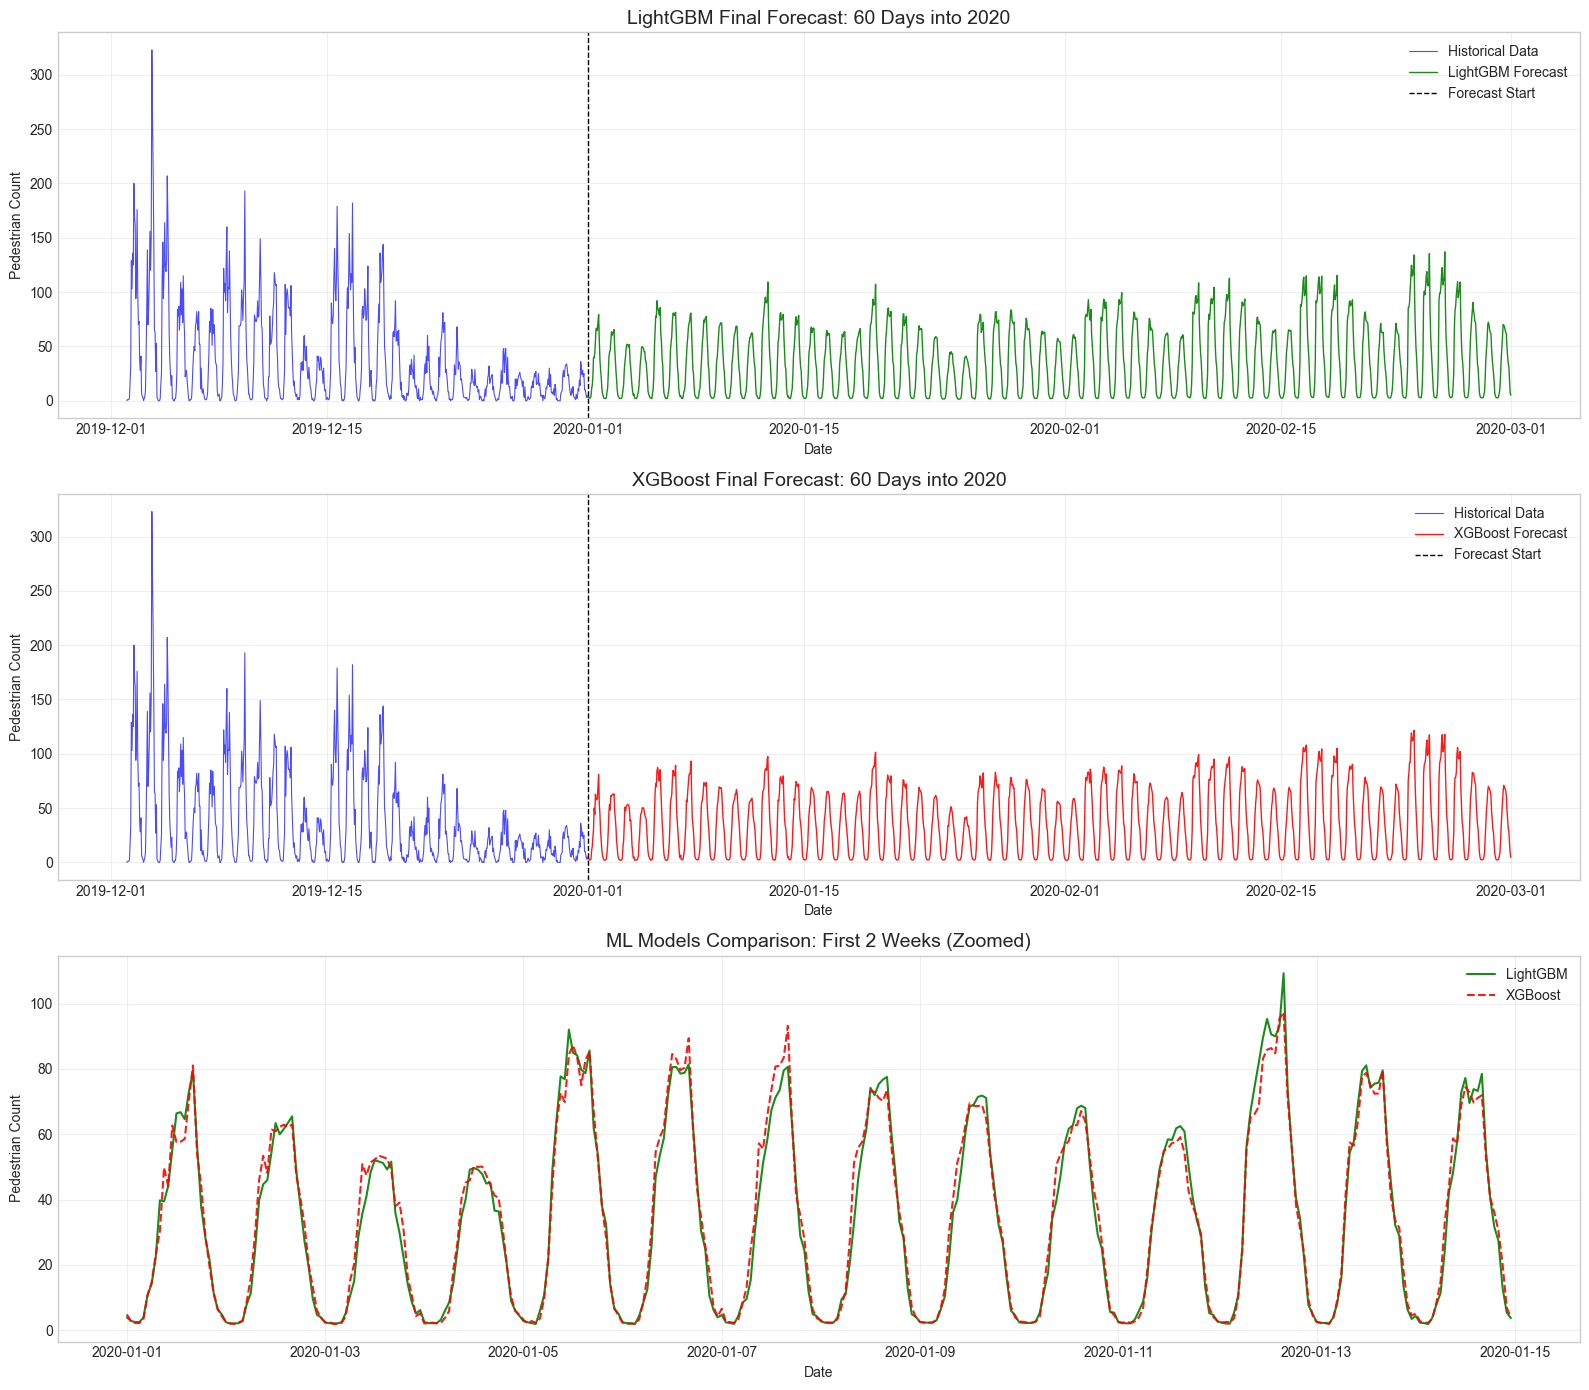

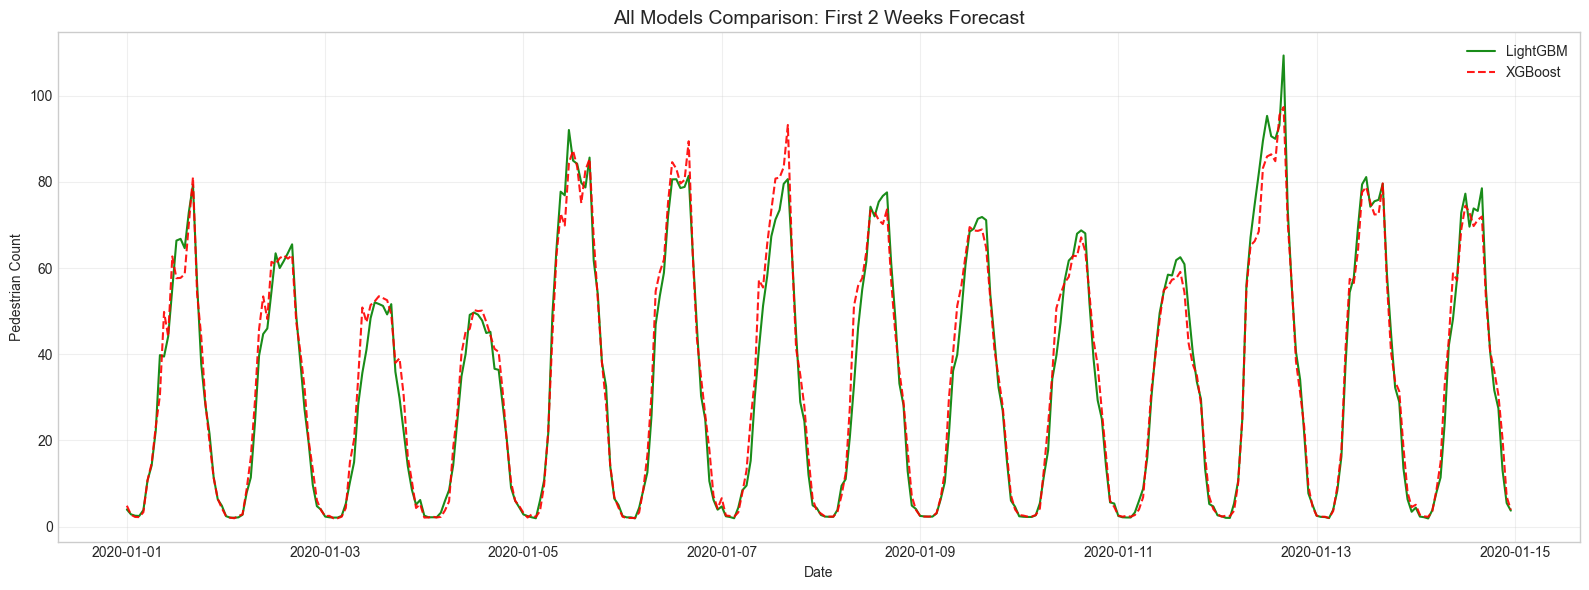

In [ ]:
# =============================================================================
# ML MODELS - PART 9: VISUALIZE FINAL FORECASTS
# =============================================================================

fig, axes = plt.subplots(3, 1, figsize=(16, 14))

# Last 30 days of training data for context
context_data = y_full.iloc[-720:]

# Plot 1: LightGBM Final Forecast
ax1 = axes[0]
ax1.plot(context_data.index, context_data.values, 
         label='Historical Data', alpha=0.7, linewidth=0.8, color='blue')
ax1.plot(lgb_final_forecast_df.index, lgb_final_forecast_df['forecast'], 
         label='LightGBM Forecast', alpha=0.9, linewidth=1, color='green')
ax1.axvline(x=y_full.index.max(), color='black', linestyle='--', 
            linewidth=1, label='Forecast Start')
ax1.set_title('LightGBM Final Forecast: 60 Days into 2020', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Pedestrian Count')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Plot 2: XGBoost Final Forecast
ax2 = axes[1]
ax2.plot(context_data.index, context_data.values, 
         label='Historical Data', alpha=0.7, linewidth=0.8, color='blue')
ax2.plot(xgb_final_forecast_df.index, xgb_final_forecast_df['forecast'], 
         label='XGBoost Forecast', alpha=0.9, linewidth=1, color='red')
ax2.axvline(x=y_full.index.max(), color='black', linestyle='--', 
            linewidth=1, label='Forecast Start')
ax2.set_title('XGBoost Final Forecast: 60 Days into 2020', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Pedestrian Count')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

# Plot 3: Both ML Models Comparison (First 2 weeks)
first_two_weeks = slice(0, 336)
ax3 = axes[2]
ax3.plot(lgb_final_forecast_df.index[first_two_weeks], 
         lgb_final_forecast_df['forecast'].values[first_two_weeks], 
         label='LightGBM', alpha=0.9, linewidth=1.5, color='green')
ax3.plot(xgb_final_forecast_df.index[first_two_weeks], 
         xgb_final_forecast_df['forecast'].values[first_two_weeks], 
         label='XGBoost', alpha=0.9, linewidth=1.5, color='red', linestyle='--')
ax3.set_title('ML Models Comparison: First 2 Weeks (Zoomed)', fontsize=14)
ax3.set_xlabel('Date')
ax3.set_ylabel('Pedestrian Count')
ax3.legend(loc='upper right')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Additional plot: All 4 models together (first 2 weeks)
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(lgb_final_forecast_df.index[first_two_weeks], 
        lgb_final_forecast_df['forecast'].values[first_two_weeks], 
        label='LightGBM', alpha=0.9, linewidth=1.5, color='green')
ax.plot(xgb_final_forecast_df.index[first_two_weeks], 
        xgb_final_forecast_df['forecast'].values[first_two_weeks], 
        label='XGBoost', alpha=0.9, linewidth=1.5, color='red', linestyle='--')

ax.set_title('All Models Comparison: First 2 Weeks Forecast', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Pedestrian Count')
ax.legend(loc='upper right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## Part 2: SARIMA with Box-Cox Transformation
---

In [1]:
# =============================================================================
# PART 1: IMPORTS AND DATA PREPARATION
# =============================================================================

# Core libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time series
import pmdarima as pm
from pmdarima.preprocessing import FourierFeaturizer
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

# Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

In [2]:
# =============================================================================
# LOAD DATA
# =============================================================================

# Load dataset 
df = pd.read_csv("C:\\Users\\kekko\\Downloads\\student_dataset.csv")
df = df.rename(columns={'time': 'date'})

# Ensure 'date' is datetime and set as index
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')
df = df.sort_index()

print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"First few rows:\n{df.head()}")

Dataset shape: (42767, 1)
Date range: 2015-04-15 00:00:01 to 2020-02-29 22:00:01
First few rows:
                     value
date                      
2015-04-15 00:00:01   13.0
2015-04-15 01:00:01    2.0
2015-04-15 02:00:01    5.0
2015-04-15 03:00:01    3.0
2015-04-15 04:00:01    8.0


In [3]:
# =============================================================================
# Reduce dataset size for computational efficiency
# =============================================================================

# Percentage of data to KEEP (from the end of the dataset)
# Change this value to adjust the reduction (e.g. 0.5 = 50%, 0.2 = 20%)
KEEP_PERCENTAGE = 0.9

cutoff_index = int(len(df) * (1 - KEEP_PERCENTAGE))
df = df.iloc[cutoff_index:]

print(f"Kept last {KEEP_PERCENTAGE*100}% of data")
print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"First few rows:\n{df.head()}")

Kept last 90.0% of data
Dataset shape: (38491, 1)
Date range: 2015-10-10 04:00:01 to 2020-02-29 22:00:01
First few rows:
                     value
date                      
2015-10-10 04:00:01   53.0
2015-10-10 05:00:01  111.0
2015-10-10 06:00:01  115.0
2015-10-10 07:00:01  154.0
2015-10-10 08:00:01  137.0


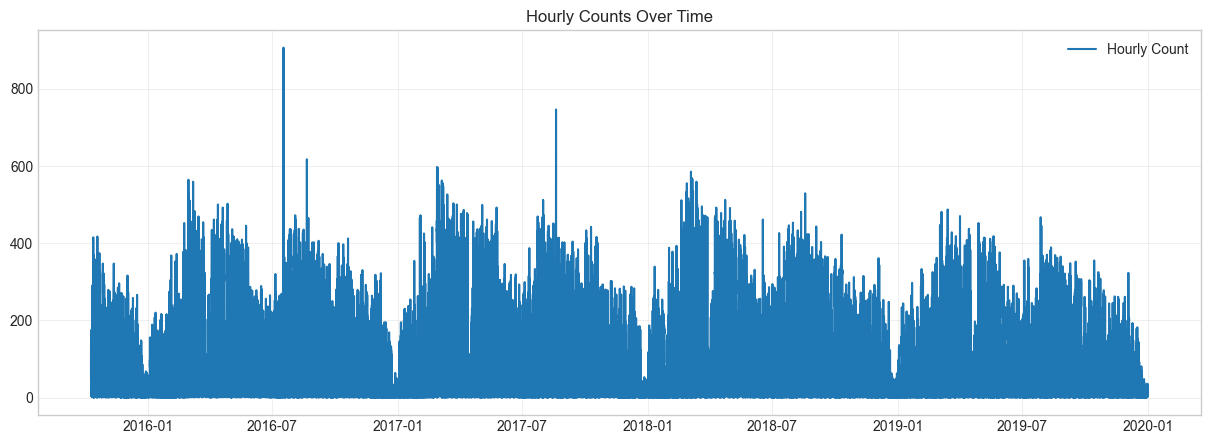

In [4]:
# Plot the dataset
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'], label='Hourly Count', color='#1f77b4')
plt.title('Hourly Counts Over Time')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [5]:
# =============================================================================
# PART 2: TRAIN / VALIDATION / TEST SPLIT
# =============================================================================

# Define split sizes
FORECAST_HORIZON = 1440  # 60 days * 24 hours

# Identify where the actual values end (before missing values)
# Based on your info: training data ends Dec 31, 2019
# The missing 1440 values are AFTER this date

# Split the data that HAS values
df_with_values = df[df['value'].notna()].copy()

print(f"Data with values: {len(df_with_values)} observations")
print(f"Date range with values: {df_with_values.index.min()} to {df_with_values.index.max()}")

# Create splits
# Test set: We don't have values yet (the 1440 missing ones) - we'll forecast these
# Validation set: Last 1440 observations WITH values (for hyperparameter tuning)
# Training set: Everything before validation

train_end_idx = len(df_with_values) - FORECAST_HORIZON
val_end_idx = len(df_with_values)

train = df_with_values.iloc[:train_end_idx].copy()
validation = df_with_values.iloc[train_end_idx:val_end_idx].copy()

print(f"\n{'='*60}")
print(f"SPLIT SUMMARY")
print(f"{'='*60}")
print(f"Training set:   {len(train):,} obs | {train.index.min()} to {train.index.max()}")
print(f"Validation set: {len(validation):,} obs | {validation.index.min()} to {validation.index.max()}")
print(f"Test set:       {FORECAST_HORIZON:,} obs | To be forecasted (Jan-Feb 2020)")
print(f"{'='*60}")

# Extract the series
y_train = train['value']
y_val = validation['value']

Data with values: 37052 observations
Date range with values: 2015-10-10 04:00:01 to 2019-12-31 23:00:01

SPLIT SUMMARY
Training set:   35,612 obs | 2015-10-10 04:00:01 to 2019-11-01 23:00:01
Validation set: 1,440 obs | 2019-11-02 00:00:01 to 2019-12-31 23:00:01
Test set:       1,440 obs | To be forecasted (Jan-Feb 2020)


In [6]:
# =============================================================================
# PART 3: FOURIER FEATURES FOR WEEKLY SEASONALITY
# =============================================================================

# SARIMA will handle daily seasonality (m=24)
# Fourier terms will handle weekly seasonality (period=168)

# We'll test different K values (number of Fourier pairs)
# K=1: captures basic weekly pattern
# K=2-3: captures more complex weekly patterns
# K=4: very flexible (risk of overfitting)

WEEKLY_PERIOD = 168  # 7 days * 24 hours
FOURIER_K = 3  # Number of Fourier pairs (we'll tune this)

def create_fourier_features(index, period, k):
    """
    Create Fourier features for a given period.
    
    Parameters:
    -----------
    index : DatetimeIndex
        The datetime index
    period : int
        The seasonal period (168 for weekly with hourly data)
    k : int
        Number of Fourier pairs (sin/cos)
    
    Returns:
    --------
    DataFrame with Fourier features
    """
    n = len(index)
    t = np.arange(n)
    
    fourier_features = pd.DataFrame(index=index)
    
    for i in range(1, k + 1):
        fourier_features[f'sin_{period}_{i}'] = np.sin(2 * np.pi * i * t / period)
        fourier_features[f'cos_{period}_{i}'] = np.cos(2 * np.pi * i * t / period)
    
    return fourier_features

# Create Fourier features for training and validation
fourier_train = create_fourier_features(train.index, WEEKLY_PERIOD, FOURIER_K)
fourier_val = create_fourier_features(validation.index, WEEKLY_PERIOD, FOURIER_K)

print(f"Fourier features created with K={FOURIER_K} pairs")
print(f"Feature columns: {list(fourier_train.columns)}")
print(f"\nTraining Fourier shape: {fourier_train.shape}")
print(f"Validation Fourier shape: {fourier_val.shape}")

# Preview
print(f"\nFourier features preview:\n{fourier_train.head()}")

Fourier features created with K=3 pairs
Feature columns: ['sin_168_1', 'cos_168_1', 'sin_168_2', 'cos_168_2', 'sin_168_3', 'cos_168_3']

Training Fourier shape: (35612, 6)
Validation Fourier shape: (1440, 6)

Fourier features preview:
                     sin_168_1  cos_168_1  sin_168_2  cos_168_2  sin_168_3  \
date                                                                         
2015-10-10 04:00:01   0.000000   1.000000   0.000000   1.000000   0.000000   
2015-10-10 05:00:01   0.037391   0.999301   0.074730   0.997204   0.111964   
2015-10-10 06:00:01   0.074730   0.997204   0.149042   0.988831   0.222521   
2015-10-10 07:00:01   0.111964   0.993712   0.222521   0.974928   0.330279   
2015-10-10 08:00:01   0.149042   0.988831   0.294755   0.955573   0.433884   

                     cos_168_3  
date                            
2015-10-10 04:00:01   1.000000  
2015-10-10 05:00:01   0.993712  
2015-10-10 06:00:01   0.974928  
2015-10-10 07:00:01   0.943883  
2015-10-10 08:00:01 

In [ ]:
# =============================================================================
# PART 3a: BOX-COX TRANSFORMATION
# =============================================================================
from scipy.stats import boxcox
from scipy.special import inv_boxcox

print(f"Applying Box-Cox Transformation to stabilize variance...")

# 1. Handle non-positive values
# Box-Cox requires strictly positive data (> 0). 
# If we have 0 or negative values, we add an offset constant.
if y_train.min() <= 0:
    # Add offset so the minimum value becomes 1.0
    # For count data with zeros, usually adding 1 is sufficient
    offset = 1.0 - y_train.min()
    print(f"Data contains non-positive values (min: {y_train.min()}).")
    print(f"Adding offset of {offset} to all data before transformation.")
else:
    offset = 0.0

# 2. Apply Box-Cox on training data
# This finds the optimal lambda that maximizes log-likelihood
y_train_shifted = y_train + offset
y_train_transformed, lam = boxcox(y_train_shifted)

# Store original y_train just in case
y_train_original = y_train.copy()

# Update y_train with transformed values for the model
y_train = pd.Series(y_train_transformed, index=y_train.index)

print(f"\nOptimal Lambda found: {lam:.4f}")
if np.isclose(lam, 0, atol=0.05):
    print("Lambda is close to 0, which corresponds to Log Transformation.")
elif np.isclose(lam, 1, atol=0.05):
    print("Lambda is close to 1, implying limited need for transformation.")
    
print(f"Transformed Training Data Range: {y_train.min():.4f} to {y_train.max():.4f}")

# 3. Define helper for inverse transformation (for predictions)
def inverse_boxcox(y_transformed, lambda_, offset_):
    """
    Inverse Box-Cox transformation to get back to original scale.
    """
    y_inv = inv_boxcox(y_transformed, lambda_)
    return y_inv - offset_

print("\nNOTE: y_train is now transformed.")
print("The model will be trained on the Box-Cox transformed data.")
print("We must inverse-transform predictions using 'inverse_boxcox' to compare with actuals.")

In [7]:
# =============================================================================
# PART 4 (SIMPLEST): BASELINE MODEL
# =============================================================================

# Start with a simple, commonly effective model for hourly data
# Based on your ACF/PACF: SARIMA(1,0,1)(1,1,1)[24]

print("Fitting baseline SARIMA(1,0,1)(1,1,1)[24] model...")

baseline_model = SARIMAX(
    y_train,
    exog=fourier_train,
    order=(1, 0, 1),  # AR(1), no differencing, MA(1)
    seasonal_order=(1, 1, 1, 24),  # Seasonal AR(1), diff(1), MA(1), period=24
    enforce_stationarity=False,
    enforce_invertibility=False
)

auto_arima_model = baseline_model.fit(disp=False, maxiter=100)

print("\n" + "=" * 60)
print("BASELINE MODEL FITTED")
print("=" * 60)
print(auto_arima_model.summary())

best_order = (1, 0, 1)
best_seasonal_order = (1, 1, 1, 24)

print(f"\nOrder (p,d,q): {best_order}")
print(f"Seasonal Order (P,D,Q,m): {best_seasonal_order}")
print(f"AIC: {auto_arima_model.aic:.2f}")

Fitting baseline SARIMA(1,0,1)(1,1,1)[24] model...


c:\Users\kekko\Downloads\Python\.venv_3.13\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
c:\Users\kekko\Downloads\Python\.venv_3.13\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)



BASELINE MODEL FITTED
                                     SARIMAX Results                                      
Dep. Variable:                              value   No. Observations:                35612
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 24)   Log Likelihood             -172558.869
Date:                            Thu, 05 Feb 2026   AIC                         345139.738
Time:                                    17:45:43   BIC                         345233.007
Sample:                                10-10-2015   HQIC                        345169.424
                                     - 11-01-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin_168_1      0.7303      1.256      0.581      0.561      -1.731       3.192
cos_168_1   

In [ ]:
# =============================================================================
# PART 5: VALIDATION - FORECAST AND EVALUATE
# =============================================================================

# Generate forecasts for validation period
print(f"\nGenerating {FORECAST_HORIZON}-step forecast for validation...")

# Forecast using the statsmodels object (Baseline)
# We use get_forecast for out-of-sample predictions
# Note: logical check to handle either library (Statsmodels vs Pmdarima)
if hasattr(auto_arima_model, 'get_forecast'):
    # Statsmodels syntax
    forecast_result = auto_arima_model.get_forecast(
        steps=FORECAST_HORIZON,
        exog=fourier_val
    )
    val_forecast = forecast_result.predicted_mean
else:
    # Pmdarima syntax
    val_forecast = auto_arima_model.predict(
        n_periods=FORECAST_HORIZON,
        X=fourier_val
    )

# INVERSE BOX-COX TRANSFORM IF APPLIED
# Check if we have transformed the training data 
if 'lam' in locals() and 'offset' in locals():
    print(f"Inverse transforming validation forecast using lambda={lam:.4f}")
    val_forecast = inverse_boxcox(val_forecast, lam, offset)

# Create forecast DataFrame
val_forecast_df = pd.DataFrame({
    'actual': y_val.values,
    'forecast': val_forecast,
    'date': y_val.index
}).set_index('date')

# Calculate metrics
def calculate_metrics(actual, predicted, name=""):
    """Calculate and print forecast metrics."""
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    mape = mean_absolute_percentage_error(actual, predicted) * 100
    
    # Handle MAPE for zero values
    mask = actual > 0
    mape_nonzero = mean_absolute_percentage_error(actual[mask], predicted[mask]) * 100
    
    print(f"\n{'='*50}")
    print(f"METRICS {name}")
    print(f"{'='*50}")
    print(f"RMSE:  {rmse:.2f}")
    print(f"MAE:   {mae:.2f}")
    print(f"MAPE:  {mape:.2f}% (all data)")
    print(f"MAPE:  {mape_nonzero:.2f}% (excluding zeros)")
    print(f"{'='*50}")
    
    return {'rmse': rmse, 'mae': mae, 'mape': mape, 'mape_nonzero': mape_nonzero}

sarima_metrics = calculate_metrics(
    val_forecast_df['actual'], 
    val_forecast_df['forecast'],
    name="SARIMA VALIDATION"
)


Generating 1440-step forecast for validation...

METRICS SARIMA VALIDATION
RMSE:  53.26
MAE:   41.46
MAPE:  591901900199051904.00% (all data)
MAPE:  416.96% (excluding zeros)


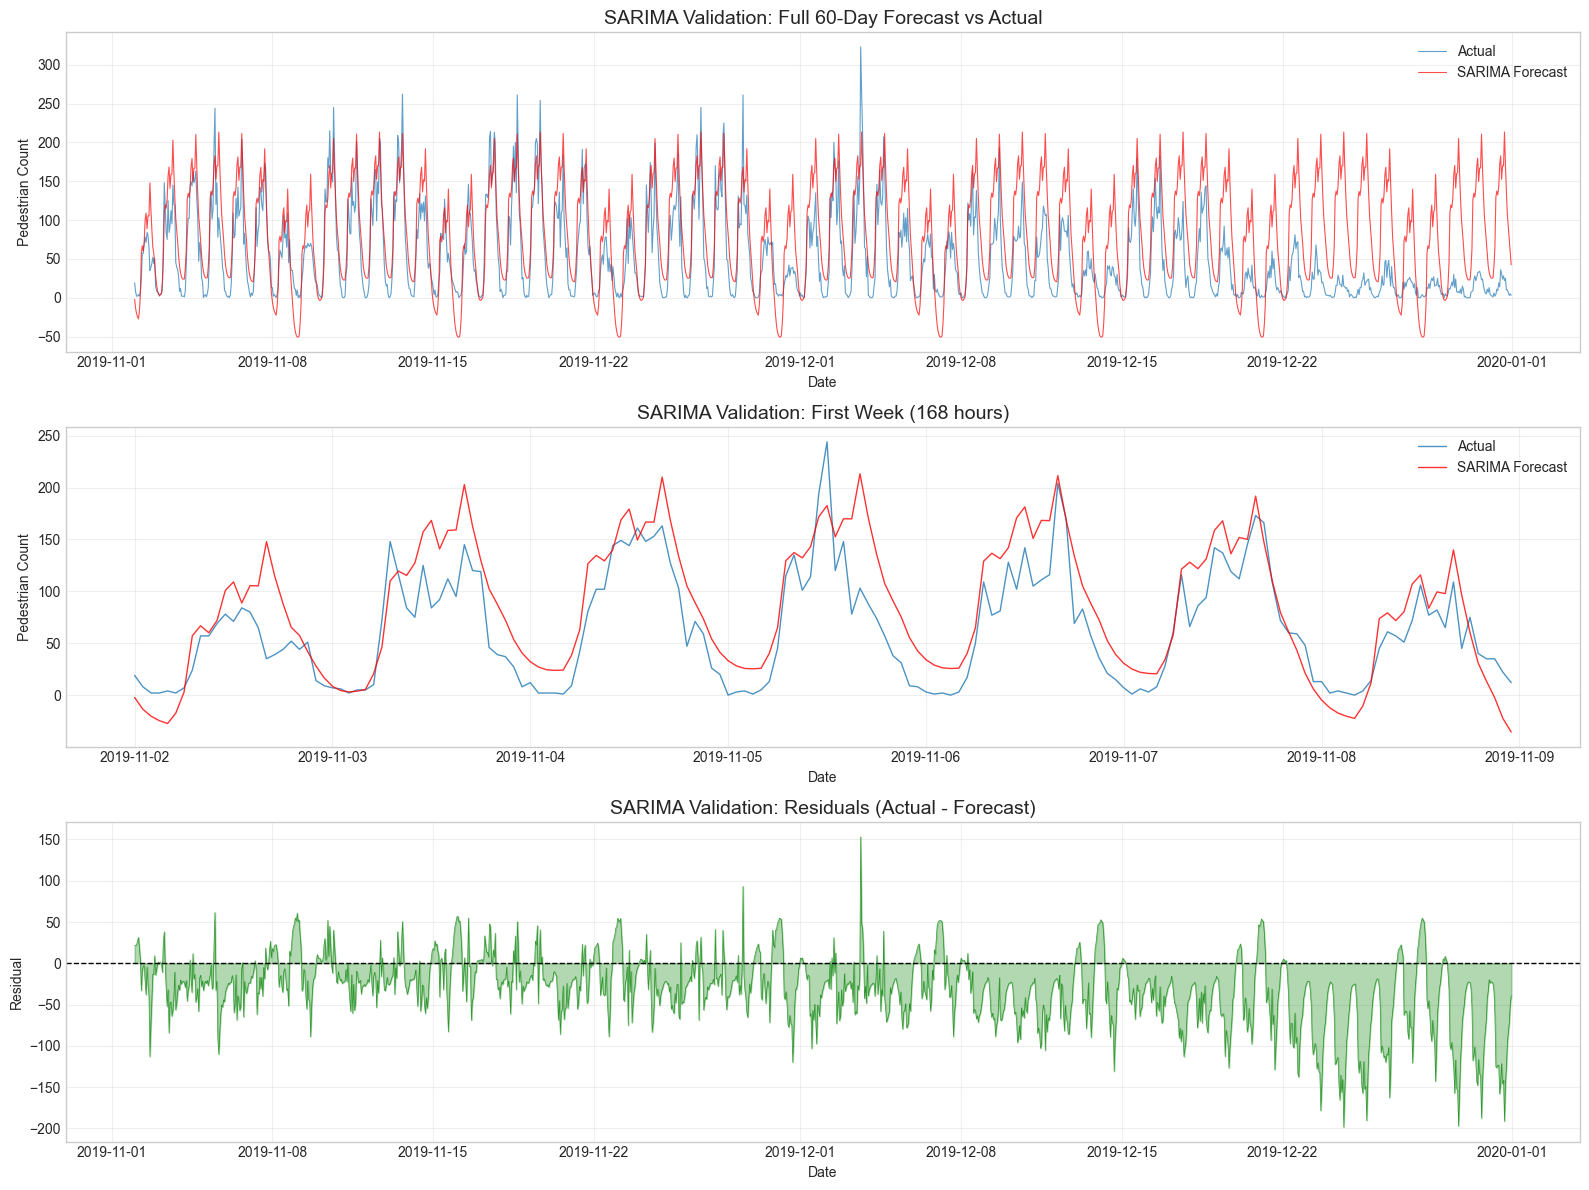

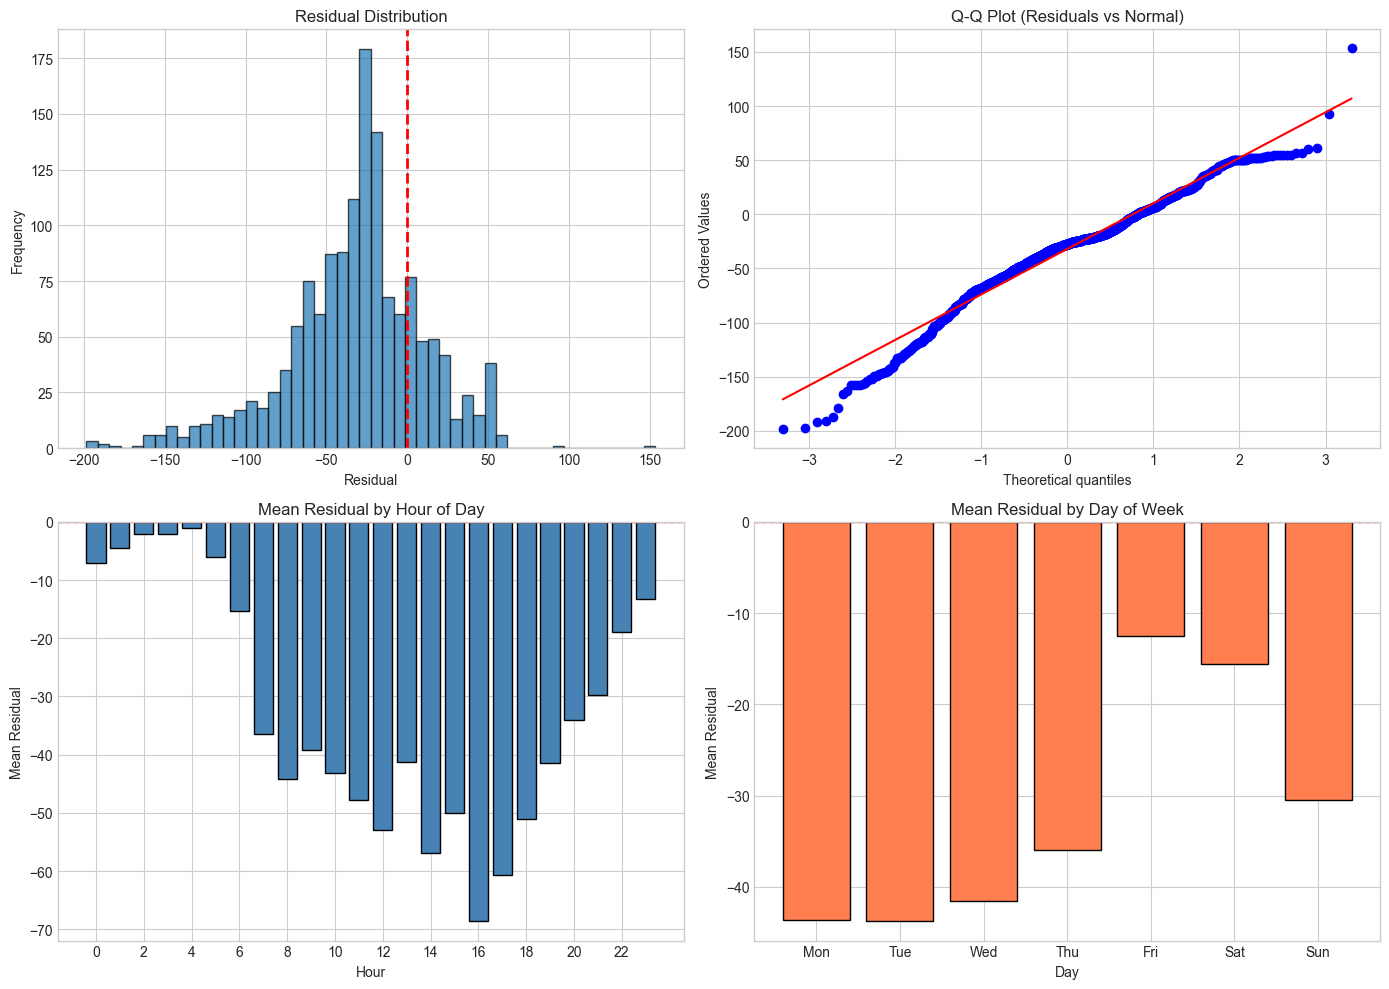

In [9]:
# =============================================================================
# PART 6: VISUALIZATION
# =============================================================================

# Plot 1: Full validation period
fig, axes = plt.subplots(3, 1, figsize=(16, 12))

# Plot 1a: Full validation forecast vs actual
ax1 = axes[0]
ax1.plot(val_forecast_df.index, val_forecast_df['actual'], 
         label='Actual', alpha=0.7, linewidth=0.8)
ax1.plot(val_forecast_df.index, val_forecast_df['forecast'], 
         label='SARIMA Forecast', alpha=0.7, linewidth=0.8, color='red')
ax1.set_title('SARIMA Validation: Full 60-Day Forecast vs Actual', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Pedestrian Count')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 1b: First week zoom
first_week = val_forecast_df.iloc[:168]  # First 7 days
ax2 = axes[1]
ax2.plot(first_week.index, first_week['actual'], 
         label='Actual', alpha=0.8, linewidth=1)
ax2.plot(first_week.index, first_week['forecast'], 
         label='SARIMA Forecast', alpha=0.8, linewidth=1, color='red')
ax2.set_title('SARIMA Validation: First Week (168 hours)', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Pedestrian Count')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 1c: Residuals
residuals = val_forecast_df['actual'] - val_forecast_df['forecast']
ax3 = axes[2]
ax3.plot(val_forecast_df.index, residuals, alpha=0.7, linewidth=0.5, color='green')
ax3.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax3.fill_between(val_forecast_df.index, residuals, 0, alpha=0.3, color='green')
ax3.set_title('SARIMA Validation: Residuals (Actual - Forecast)', fontsize=14)
ax3.set_xlabel('Date')
ax3.set_ylabel('Residual')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Plot 2: Residual diagnostics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Residual histogram
ax1 = axes[0, 0]
ax1.hist(residuals, bins=50, edgecolor='black', alpha=0.7)
ax1.axvline(x=0, color='red', linestyle='--', linewidth=2)
ax1.set_title('Residual Distribution')
ax1.set_xlabel('Residual')
ax1.set_ylabel('Frequency')

# Residual QQ plot
from scipy import stats
ax2 = axes[0, 1]
stats.probplot(residuals, dist="norm", plot=ax2)
ax2.set_title('Q-Q Plot (Residuals vs Normal)')

# Residuals by hour of day
val_forecast_df['hour'] = val_forecast_df.index.hour
hourly_residuals = val_forecast_df.groupby('hour').apply(
    lambda x: (x['actual'] - x['forecast']).mean()
)
ax3 = axes[1, 0]
ax3.bar(hourly_residuals.index, hourly_residuals.values, color='steelblue', edgecolor='black')
ax3.axhline(y=0, color='red', linestyle='--', linewidth=1)
ax3.set_title('Mean Residual by Hour of Day')
ax3.set_xlabel('Hour')
ax3.set_ylabel('Mean Residual')
ax3.set_xticks(range(0, 24, 2))

# Residuals by day of week
val_forecast_df['dayofweek'] = val_forecast_df.index.dayofweek
daily_residuals = val_forecast_df.groupby('dayofweek').apply(
    lambda x: (x['actual'] - x['forecast']).mean()
)
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
ax4 = axes[1, 1]
ax4.bar(range(7), daily_residuals.values, color='coral', edgecolor='black')
ax4.axhline(y=0, color='red', linestyle='--', linewidth=1)
ax4.set_title('Mean Residual by Day of Week')
ax4.set_xlabel('Day')
ax4.set_ylabel('Mean Residual')
ax4.set_xticks(range(7))
ax4.set_xticklabels(day_names)

plt.tight_layout()
plt.show()

In [ ]:
# =============================================================================
# PART 7: RETRAIN ON FULL DATA & FINAL FORECAST
# =============================================================================

# Now that we've validated our model, retrain on ALL available data
# (training + validation) before making the final forecast

print("Retraining SARIMA on full data (train + validation)...")

# Combine train and validation
full_train = pd.concat([train, validation])
y_full = full_train['value']

# APPLY BOX-COX IF IT WAS USED BEFORE
if 'lam' in locals() and 'offset' in locals():
    print(f"Applying Box-Cox to full dataset with lambda={lam:.4f}")
    y_full_shifted = y_full + offset
    # Use the same lambda as found in training for consistency
    y_full_transformed = boxcox(y_full_shifted, lmbda=lam)
    y_full = pd.Series(y_full_transformed, index=y_full.index)

# Create Fourier features for full training data
fourier_full = create_fourier_features(full_train.index, WEEKLY_PERIOD, FOURIER_K)

# Fit final model with best parameters found by auto_arima
final_model = SARIMAX(
    y_full,
    exog=fourier_full,
    order=best_order,
    seasonal_order=best_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

final_model_fit = final_model.fit(disp=False)

print("\nFinal Model Summary:")
print(final_model_fit.summary())

Retraining SARIMA on full data (train + validation)...


c:\Users\kekko\Downloads\Python\.venv_3.13\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
c:\Users\kekko\Downloads\Python\.venv_3.13\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)



Final Model Summary:
                                     SARIMAX Results                                      
Dep. Variable:                              value   No. Observations:                37052
Model:             SARIMAX(1, 0, 1)x(1, 1, 1, 24)   Log Likelihood             -179123.467
Date:                            Thu, 05 Feb 2026   AIC                         358268.933
Time:                                    17:51:47   BIC                         358362.639
Sample:                                10-10-2015   HQIC                        358298.703
                                     - 12-31-2019                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin_168_1      0.8520      1.218      0.699      0.484      -1.536       3.240
cos_168_1    

In [ ]:
# =============================================================================
# GENERATE FORECAST FOR TEST PERIOD (the 1440 missing values)
# =============================================================================

# Create future dates for forecast period
last_date = full_train.index.max()
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(hours=1),
    periods=FORECAST_HORIZON,
    freq='H'
)

print(f"\nForecast period: {future_dates.min()} to {future_dates.max()}")

# Create Fourier features for forecast period
# IMPORTANT: We need to continue the Fourier sequence properly
def create_fourier_features_forecast(future_index, train_index, period, k):
    """
    Create Fourier features for forecast period, continuing from training.
    """
    # Total length from start of training to end of forecast
    n_train = len(train_index)
    n_forecast = len(future_index)
    
    # Time indices for forecast (continuing from training)
    t = np.arange(n_train, n_train + n_forecast)
    
    fourier_features = pd.DataFrame(index=future_index)
    
    for i in range(1, k + 1):
        fourier_features[f'sin_{period}_{i}'] = np.sin(2 * np.pi * i * t / period)
        fourier_features[f'cos_{period}_{i}'] = np.cos(2 * np.pi * i * t / period)
    
    return fourier_features

fourier_forecast = create_fourier_features_forecast(
    future_dates, full_train.index, WEEKLY_PERIOD, FOURIER_K
)

# Generate final forecast
final_forecast = final_model_fit.get_forecast(
    steps=FORECAST_HORIZON,
    exog=fourier_forecast
)

# Extract predictions and confidence intervals
forecast_mean = final_forecast.predicted_mean
forecast_ci = final_forecast.conf_int(alpha=0.05)  # 95% CI

# INVERSE BOX-COX TRANSFORM IF APPLIED
if 'lam' in locals() and 'offset' in locals():
    print(f"Inverse transforming final forecast using lambda={lam:.4f}")
    forecast_mean = inverse_boxcox(forecast_mean, lam, offset)
    forecast_ci = inverse_boxcox(forecast_ci, lam, offset)

# Create forecast DataFrame
final_forecast_df = pd.DataFrame({
    'date': future_dates,
    'forecast': forecast_mean.values,
    'lower_ci': forecast_ci.iloc[:, 0].values,
    'upper_ci': forecast_ci.iloc[:, 1].values
}).set_index('date')

# Clip negative forecasts to 0 (counts can't be negative)
final_forecast_df['forecast'] = final_forecast_df['forecast'].clip(lower=0)
final_forecast_df['lower_ci'] = final_forecast_df['lower_ci'].clip(lower=0)
final_forecast_df['upper_ci'] = final_forecast_df['upper_ci'].clip(lower=0)

print(f"\nFinal Forecast Summary:")
print(final_forecast_df.describe())


Forecast period: 2020-01-01 00:00:01 to 2020-02-29 23:00:01

Final Forecast Summary:
          forecast  lower_ci     upper_ci
count  1440.000000    1440.0  1440.000000
mean     29.944036       0.0   136.017589
std      25.738631       0.0    34.893018
min       0.000000       0.0    45.303642
25%       4.699333       0.0   112.931362
50%      22.497814       0.0   137.025831
75%      54.599968       0.0   164.483386
max      82.179219       0.0   204.691610


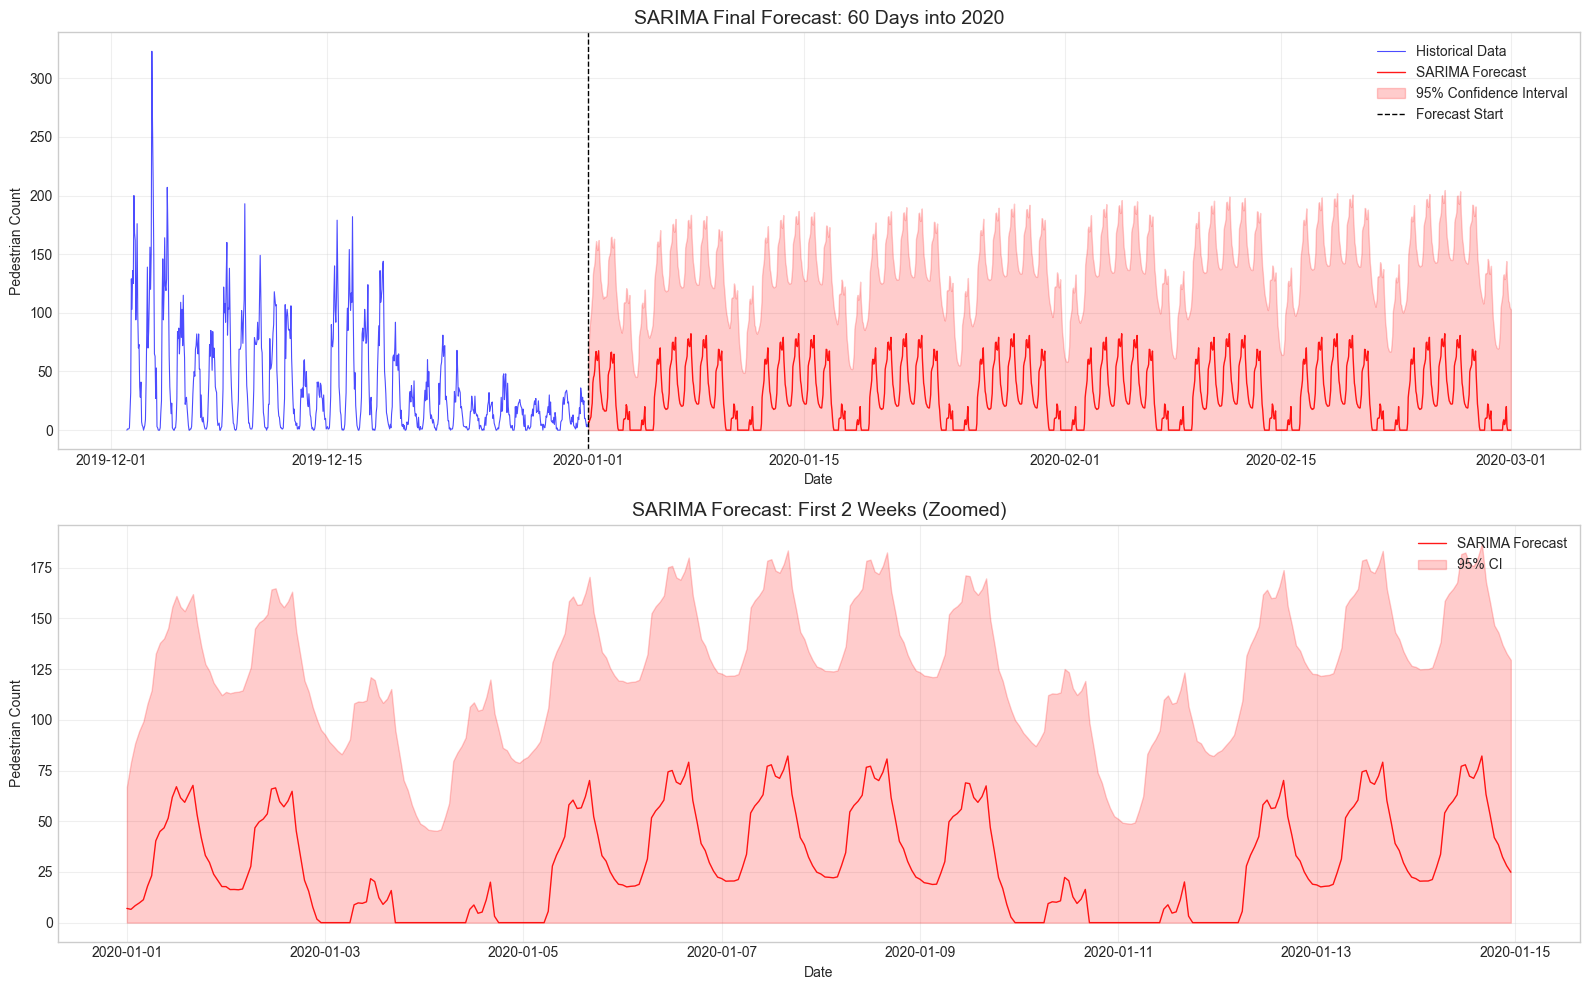

In [12]:
# =============================================================================
# PART 8: VISUALIZE FINAL FORECAST
# =============================================================================

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Plot 1: Historical data + Forecast
ax1 = axes[0]

# Last 30 days of training data for context
context_data = full_train.iloc[-720:]  # Last 30 days

ax1.plot(context_data.index, context_data['value'], 
         label='Historical Data', alpha=0.7, linewidth=0.8, color='blue')
ax1.plot(final_forecast_df.index, final_forecast_df['forecast'], 
         label='SARIMA Forecast', alpha=0.9, linewidth=1, color='red')
ax1.fill_between(final_forecast_df.index, 
                  final_forecast_df['lower_ci'], 
                  final_forecast_df['upper_ci'],
                  alpha=0.2, color='red', label='95% Confidence Interval')
ax1.axvline(x=full_train.index.max(), color='black', linestyle='--', 
            linewidth=1, label='Forecast Start')
ax1.set_title('SARIMA Final Forecast: 60 Days into 2020', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Pedestrian Count')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Plot 2: First 2 weeks of forecast (zoomed)
first_two_weeks = final_forecast_df.iloc[:336]  # 14 days
ax2 = axes[1]
ax2.plot(first_two_weeks.index, first_two_weeks['forecast'], 
         label='SARIMA Forecast', alpha=0.9, linewidth=1, color='red')
ax2.fill_between(first_two_weeks.index, 
                  first_two_weeks['lower_ci'], 
                  first_two_weeks['upper_ci'],
                  alpha=0.2, color='red', label='95% CI')
ax2.set_title('SARIMA Forecast: First 2 Weeks (Zoomed)', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Pedestrian Count')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# =============================================================================
# PART 4: AUTO ARIMA - THOROUGH SEARCH
# =============================================================================

# This will take a while due to thorough search!
# We're searching for best (p,d,q)(P,D,Q)[24] with Fourier exogenous variables

print("Starting Auto ARIMA search (this may take 10-30+ minutes)...")
print("Parameters: m=24 (daily seasonality), d=0 (stationary), thorough search")
print("-" * 60)

# Thorough search parameters
auto_arima_model = pm.auto_arima(
    y_train,
    
    # Exogenous variables (Fourier terms for weekly seasonality)
    X=fourier_train,
    
    # Seasonal settings
    seasonal=True,
    m=24,  # Daily seasonality (24 hours)
    
    # Differencing
    d=0,  # Non-seasonal differencing (already stationary based on ADF)
    D=None,  # Let auto_arima decide seasonal differencing (will test 0 and 1)
    max_D=1,
    
    # AR and MA ranges (thorough search)
    start_p=0,
    max_p=4,
    start_q=0,
    max_q=4,
    
    # Seasonal AR and MA ranges
    start_P=0,
    max_P=3,
    start_Q=0,
    max_Q=3,
    
    # Search settings
    stepwise=False,  # False = exhaustive search (slower but thorough)
    n_fits=50,  # Max models to fit (increase for more thorough search)
    
    # Information criterion
    information_criterion='aic',
    
    # Other settings
    trace=True,  # Print progress
    error_action='ignore',
    suppress_warnings=True,
    
    # Parallel processing (set n_jobs=-1 to use all cores)
    n_jobs=-1
)

print("\n" + "=" * 60)
print("AUTO ARIMA RESULTS")
print("=" * 60)
print(auto_arima_model.summary())

# Store best parameters
best_order = auto_arima_model.order
best_seasonal_order = auto_arima_model.seasonal_order

print(f"\nBest Order (p,d,q): {best_order}")
print(f"Best Seasonal Order (P,D,Q,m): {best_seasonal_order}")
print(f"AIC: {auto_arima_model.aic():.2f}")

---
## Part 3: UCM with Box-Cox Transformation
---

In [1]:
# =============================================================================
# PART 1: IMPORTS AND DATA PREPARATION
# =============================================================================

# Core libraries
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time series
import pmdarima as pm
from pmdarima.preprocessing import FourierFeaturizer
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

# Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

In [2]:
# =============================================================================
# UCM MODEL - PART 1: SETUP
# =============================================================================

# Additional imports for UCM
from statsmodels.tsa.statespace.structural import UnobservedComponents
from statsmodels.graphics.tsaplots import plot_predict
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("UNOBSERVED COMPONENTS MODEL (UCM)")
print("=" * 60)
print("\nUCM explicitly models:")
print("  - Level (base pedestrian count)")
print("  - Seasonal components (24h daily, 168h weekly)")
print("  - Irregular (random noise)")
print("=" * 60)

UNOBSERVED COMPONENTS MODEL (UCM)

UCM explicitly models:
  - Level (base pedestrian count)
  - Seasonal components (24h daily, 168h weekly)
  - Irregular (random noise)


In [3]:
# =============================================================================
# LOAD DATA
# =============================================================================

# Load dataset 
df = pd.read_csv("C:\\Users\\kekko\\Downloads\\student_dataset.csv")
df = df.rename(columns={'time': 'date'})

# Ensure 'date' is datetime and set as index
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')
df = df.sort_index()

print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"First few rows:\n{df.head()}")

Dataset shape: (42767, 1)
Date range: 2015-04-15 00:00:01 to 2020-02-29 22:00:01
First few rows:
                     value
date                      
2015-04-15 00:00:01   13.0
2015-04-15 01:00:01    2.0
2015-04-15 02:00:01    5.0
2015-04-15 03:00:01    3.0
2015-04-15 04:00:01    8.0


In [4]:
# =============================================================================
# Reduce dataset size for computational efficiency
# =============================================================================

# Percentage of data to KEEP (from the end of the dataset)
# Change this value to adjust the reduction (e.g. 0.5 = 50%, 0.2 = 20%)
KEEP_PERCENTAGE = 0.6

cutoff_index = int(len(df) * (1 - KEEP_PERCENTAGE))
df = df.iloc[cutoff_index:]

print(f"Kept last {KEEP_PERCENTAGE*100}% of data")
print(f"Dataset shape: {df.shape}")
print(f"Date range: {df.index.min()} to {df.index.max()}")
print(f"First few rows:\n{df.head()}")

Kept last 60.0% of data
Dataset shape: (25661, 1)
Date range: 2017-03-27 18:00:01 to 2020-02-29 22:00:01
First few rows:
                     value
date                      
2017-03-27 18:00:01  364.0
2017-03-27 19:00:01  286.0
2017-03-27 20:00:01  193.0
2017-03-27 21:00:01  120.0
2017-03-27 22:00:01  106.0


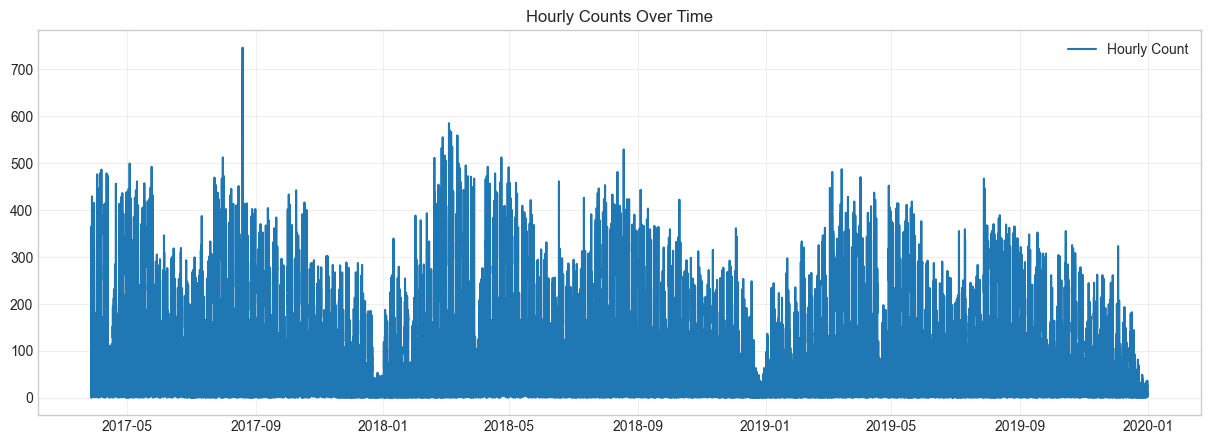

In [5]:
# Plot the dataset
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'], label='Hourly Count', color='#1f77b4')
plt.title('Hourly Counts Over Time')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [6]:
# =============================================================================
# PART 2: TRAIN / VALIDATION / TEST SPLIT
# =============================================================================

# Define split sizes
FORECAST_HORIZON = 1440  # 60 days * 24 hours

# Identify where the actual values end (before missing values)
# Based on your info: training data ends Dec 31, 2019
# The missing 1440 values are AFTER this date

# Split the data that HAS values
df_with_values = df[df['value'].notna()].copy()

print(f"Data with values: {len(df_with_values)} observations")
print(f"Date range with values: {df_with_values.index.min()} to {df_with_values.index.max()}")

# Create splits
# Test set: We don't have values yet (the 1440 missing ones) - we'll forecast these
# Validation set: Last 1440 observations WITH values (for hyperparameter tuning)
# Training set: Everything before validation

train_end_idx = len(df_with_values) - FORECAST_HORIZON
val_end_idx = len(df_with_values)

train = df_with_values.iloc[:train_end_idx].copy()
validation = df_with_values.iloc[train_end_idx:val_end_idx].copy()

print(f"\n{'='*60}")
print(f"SPLIT SUMMARY")
print(f"{'='*60}")
print(f"Training set:   {len(train):,} obs | {train.index.min()} to {train.index.max()}")
print(f"Validation set: {len(validation):,} obs | {validation.index.min()} to {validation.index.max()}")
print(f"Test set:       {FORECAST_HORIZON:,} obs | To be forecasted (Jan-Feb 2020)")
print(f"{'='*60}")

# Extract the series
y_train = train['value']
y_val = validation['value']

Data with values: 24222 observations
Date range with values: 2017-03-27 18:00:01 to 2019-12-31 23:00:01

SPLIT SUMMARY
Training set:   22,782 obs | 2017-03-27 18:00:01 to 2019-11-01 23:00:01
Validation set: 1,440 obs | 2019-11-02 00:00:01 to 2019-12-31 23:00:01
Test set:       1,440 obs | To be forecasted (Jan-Feb 2020)


In [7]:
# =============================================================================
# PART 2a: BOX-COX TRANSFORMATION
# =============================================================================
from scipy.stats import boxcox
from scipy.special import inv_boxcox

print(f"Applying Box-Cox Transformation to stabilize variance...")

# 1. Handle non-positive values
# Box-Cox requires strictly positive data (> 0). 
# If we have 0 or negative values, we add an offset constant.
if y_train.min() <= 0:
    # Add offset so the minimum value becomes 1.0
    # For count data with zeros, usually adding 1 is sufficient
    offset = 1.0 - y_train.min()
    print(f"Data contains non-positive values (min: {y_train.min()}).")
    print(f"Adding offset of {offset} to all data before transformation.")
else:
    offset = 0.0

# 2. Apply Box-Cox on training data
# This finds the optimal lambda that maximizes log-likelihood
y_train_shifted = y_train + offset
y_train_transformed, lam = boxcox(y_train_shifted)

# Store original y_train just in case
y_train_original = y_train.copy()

# Update y_train with transformed values for the model
y_train = pd.Series(y_train_transformed, index=y_train.index)

print(f"\nOptimal Lambda found: {lam:.4f}")
if np.isclose(lam, 0, atol=0.05):
    print("Lambda is close to 0, which corresponds to Log Transformation.")
elif np.isclose(lam, 1, atol=0.05):
    print("Lambda is close to 1, implying limited need for transformation.")
    
print(f"Transformed Training Data Range: {y_train.min():.4f} to {y_train.max():.4f}")

# 3. Define helper for inverse transformation (for predictions)
def inverse_boxcox(y_transformed, lambda_, offset_):
    """
    Inverse Box-Cox transformation to get back to original scale.
    """
    y_inv = inv_boxcox(y_transformed, lambda_)
    return y_inv - offset_

print("\nNOTE: y_train is now transformed.")
print("The model will be trained on the Box-Cox transformed data.")
print("We must inverse-transform predictions using 'inverse_boxcox' to compare with actuals.")

Applying Box-Cox Transformation to stabilize variance...
Data contains non-positive values (min: 0.0).
Adding offset of 1.0 to all data before transformation.

Optimal Lambda found: 0.2567
Transformed Training Data Range: 0.0000 to 17.3917

NOTE: y_train is now transformed.
The model will be trained on the Box-Cox transformed data.
We must inverse-transform predictions using 'inverse_boxcox' to compare with actuals.


In [8]:
# We'll use the SAME train/validation split as SARIMA
# These should already be defined from SARIMA code
print(f"\nUsing existing split:")
print(f"Training set:   {len(train):,} obs | {train.index.min()} to {train.index.max()}")
print(f"Validation set: {len(validation):,} obs | {validation.index.min()} to {validation.index.max()}")


Using existing split:
Training set:   22,782 obs | 2017-03-27 18:00:01 to 2019-11-01 23:00:01
Validation set: 1,440 obs | 2019-11-02 00:00:01 to 2019-12-31 23:00:01


In [9]:
# =============================================================================
# UCM MODEL - PART 3: MODEL SPECIFICATION SEARCH
# =============================================================================

# Define candidate UCM specifications
# We'll test different combinations of components

ucm_specs = [
    {
        'name': 'UCM-1: Local Level + Seasonal(24h + 168h)',
        'level': 'local level',
        'trend': False,
        'seasonal': [24, 168],  # Both daily and weekly
        'freq_seasonal': None,
        'cycle': False,
        'autoregressive': 0,
        'irregular': True
    },
    {
        'name': 'UCM-2: Local Level + Freq Seasonal',
        'level': 'local level',
        'trend': False,
        'seasonal': None,
        'freq_seasonal': [{'period': 24, 'harmonics': 4}, 
                          {'period': 168, 'harmonics': 3}],
        'cycle': False,
        'autoregressive': 0,
        'irregular': True
    },
    {
        'name': 'UCM-3: Local Level + Seasonal(24h) + AR(1)',
        'level': 'local level',
        'trend': False,
        'seasonal': 24,
        'freq_seasonal': [{'period': 168, 'harmonics': 3}],
        'cycle': False,
        'autoregressive': 1,
        'irregular': True
    },
    {
        'name': 'UCM-4: Local Level Trend + Seasonal',
        'level': 'local linear trend',
        'trend': True,
        'seasonal': [24, 168],
        'freq_seasonal': None,
        'cycle': False,
        'autoregressive': 0,
        'irregular': True
    },
]

print("\nTesting UCM model specifications...")
print("=" * 80)

ucm_results = []

for i, spec in enumerate(ucm_specs, 1):
    try:
        print(f"\n[{i}/{len(ucm_specs)}] {spec['name']}")
        print("-" * 80)
        
        # Build model specification
        model = UnobservedComponents(
            y_train,
            level=spec['level'],
            trend=spec['trend'],
            seasonal=spec['seasonal'],
            freq_seasonal=spec['freq_seasonal'],
            cycle=spec['cycle'],
            autoregressive=spec['autoregressive'],
            irregular=spec['irregular']
        )
        
        # Fit model
        print("   Fitting model...", end=' ')
        model_fit = model.fit(disp=False, maxiter=200)
        
        # Store results
        aic = model_fit.aic
        bic = model_fit.bic
        llf = model_fit.llf
        
        ucm_results.append({
            'name': spec['name'],
            'spec': spec,
            'model': model_fit,
            'aic': aic,
            'bic': bic,
            'llf': llf
        })
        
        print(f"✓")
        print(f"   AIC: {aic:,.2f} | BIC: {bic:,.2f} | LogLik: {llf:,.2f}")
        
    except Exception as e:
        print(f"✗ Failed: {str(e)[:60]}")
        continue

# Compare models
print("\n" + "=" * 80)
print("UCM MODEL COMPARISON")
print("=" * 80)

comparison_df = pd.DataFrame([
    {
        'Model': r['name'],
        'AIC': r['aic'],
        'BIC': r['bic'],
        'LogLikelihood': r['llf']
    }
    for r in ucm_results
]).sort_values('AIC')

print(comparison_df.to_string(index=False))
print("=" * 80)

# Select best model by AIC
best_ucm = min(ucm_results, key=lambda x: x['aic'])
best_ucm_model = best_ucm['model']
best_ucm_name = best_ucm['name']

print(f"\n🏆 BEST MODEL: {best_ucm_name}")
print(f"   AIC: {best_ucm['aic']:,.2f}")
print(f"   BIC: {best_ucm['bic']:,.2f}")


Testing UCM model specifications...

[1/4] UCM-1: Local Level + Seasonal(24h + 168h)
--------------------------------------------------------------------------------
✗ Failed: '>' not supported between instances of 'list' and 'int'

[2/4] UCM-2: Local Level + Freq Seasonal
--------------------------------------------------------------------------------
   Fitting model... ✓
   AIC: 67,893.32 | BIC: 67,925.46 | LogLik: -33,942.66

[3/4] UCM-3: Local Level + Seasonal(24h) + AR(1)
--------------------------------------------------------------------------------
   Fitting model... ✓
   AIC: 62,619.66 | BIC: 62,667.85 | LogLik: -31,303.83

[4/4] UCM-4: Local Level Trend + Seasonal
--------------------------------------------------------------------------------
✗ Failed: '>' not supported between instances of 'list' and 'int'

UCM MODEL COMPARISON
                                     Model          AIC          BIC  LogLikelihood
UCM-3: Local Level + Seasonal(24h) + AR(1) 62619.658467 62667

In [10]:
# =============================================================================
# UCM MODEL - PART 4: BEST MODEL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("BEST UCM MODEL SUMMARY")
print("=" * 80)
print(best_ucm_model.summary())

# Extract model components
print("\n" + "=" * 80)
print("MODEL COMPONENTS")
print("=" * 80)

# Check which components are in the model
if hasattr(best_ucm_model, 'level'):
    print("✓ Level component included")
if hasattr(best_ucm_model, 'trend'):
    print("✓ Trend component included")
if hasattr(best_ucm_model, 'seasonal'):
    print("✓ Seasonal component included")

# Parameter estimates
print("\nParameter Estimates:")
print(best_ucm_model.params)


BEST UCM MODEL SUMMARY
                                Unobserved Components Results                                 
Dep. Variable:                                      y   No. Observations:                22782
Model:                                    local level   Log Likelihood              -31303.829
                            + stochastic seasonal(24)   AIC                          62619.658
                   + stochastic freq_seasonal(168(3))   BIC                          62667.853
                                              + AR(1)   HQIC                         62635.328
Date:                                Thu, 05 Feb 2026                                         
Time:                                        19:45:07                                         
Sample:                                    03-27-2017                                         
                                         - 11-01-2019                                         
Covariance Type:          

In [11]:
# =============================================================================
# METRICS FUNCTION
# =============================================================================

def calculate_metrics(actual, forecast, name="Model"):
    """
    Calculates common time series metrics: RMSE, MAE, and MAPE.
    Handles division by zero for MAPE by initializing with valid non-zero actuals.
    """
    # Ensure inputs are numpy arrays for easier math
    y_true = np.array(actual)
    y_pred = np.array(forecast)
    
    # 1. RMSE (Root Mean Squared Error)
    rmse = np.sqrt(np.mean((y_true - y_pred)**2))
    
    # 2. MAE (Mean Absolute Error)
    mae = np.mean(np.abs(y_true - y_pred))
    
    # 3. MAPE (Mean Absolute Percentage Error) - Non-zero
    # We filter out instances where actual is 0 to avoid division by zero errors
    mask = y_true != 0
    if np.sum(mask) > 0:
        mape_nonzero = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    else:
        mape_nonzero = np.nan
        
    metrics = {
        'name': name,
        'rmse': rmse,
        'mae': mae,
        'mape_nonzero': mape_nonzero
    }
    
    # Optional: Print metrics immediately
    print(f"Metrics for {name}:")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE:  {mae:.2f}")
    print(f"MAPE: {mape_nonzero:.2f}%")
    
    return metrics


In [12]:
# =============================================================================
# UCM MODEL - PART 5: VALIDATION FORECAST
# =============================================================================

print("\n" + "=" * 80)
print("GENERATING VALIDATION FORECAST")
print("=" * 80)

# Generate forecast for validation period
ucm_forecast = best_ucm_model.forecast(steps=FORECAST_HORIZON)

# INVERSE BOX-COX TRANSFORM IF APPLIED
if 'lam' in locals() and 'offset' in locals():
    print(f"Inverse transforming validation forecast using lambda={lam:.4f}")
    ucm_forecast = inverse_boxcox(ucm_forecast, lam, offset)

# Create forecast DataFrame
ucm_val_forecast_df = pd.DataFrame({
    'actual': y_val.values,
    'forecast': ucm_forecast.values,
    'date': y_val.index
}).set_index('date')

# Clip negative forecasts to 0
ucm_val_forecast_df['forecast'] = ucm_val_forecast_df['forecast'].clip(lower=0)

# Calculate metrics
def calculate_metrics(actual, predicted, name=""):
    """Calculate and print forecast metrics."""
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    mape = mean_absolute_percentage_error(actual, predicted) * 100
    
    # Handle MAPE for zero values
    mask = actual > 0
    mape_nonzero = mean_absolute_percentage_error(actual[mask], predicted[mask]) * 100
    
    print(f"\n{'='*50}")
    print(f"METRICS {name}")
    print(f"{'='*50}")
    print(f"RMSE:  {rmse:.2f}")
    print(f"MAE:   {mae:.2f}")
    print(f"MAPE:  {mape:.2f}% (all data)")
    print(f"MAPE:  {mape_nonzero:.2f}% (excluding zeros)")
    print(f"{'='*50}")
    
    return {'rmse': rmse, 'mae': mae, 'mape': mape, 'mape_nonzero': mape_nonzero}

ucm_metrics = calculate_metrics(
    ucm_val_forecast_df['actual'], 
    ucm_val_forecast_df['forecast'],
    name="UCM VALIDATION"
)


GENERATING VALIDATION FORECAST
Inverse transforming validation forecast using lambda=0.2567

METRICS UCM VALIDATION
RMSE:  47.16
MAE:   31.11
MAPE:  67077574799258264.00% (all data)
MAPE:  154.74% (excluding zeros)


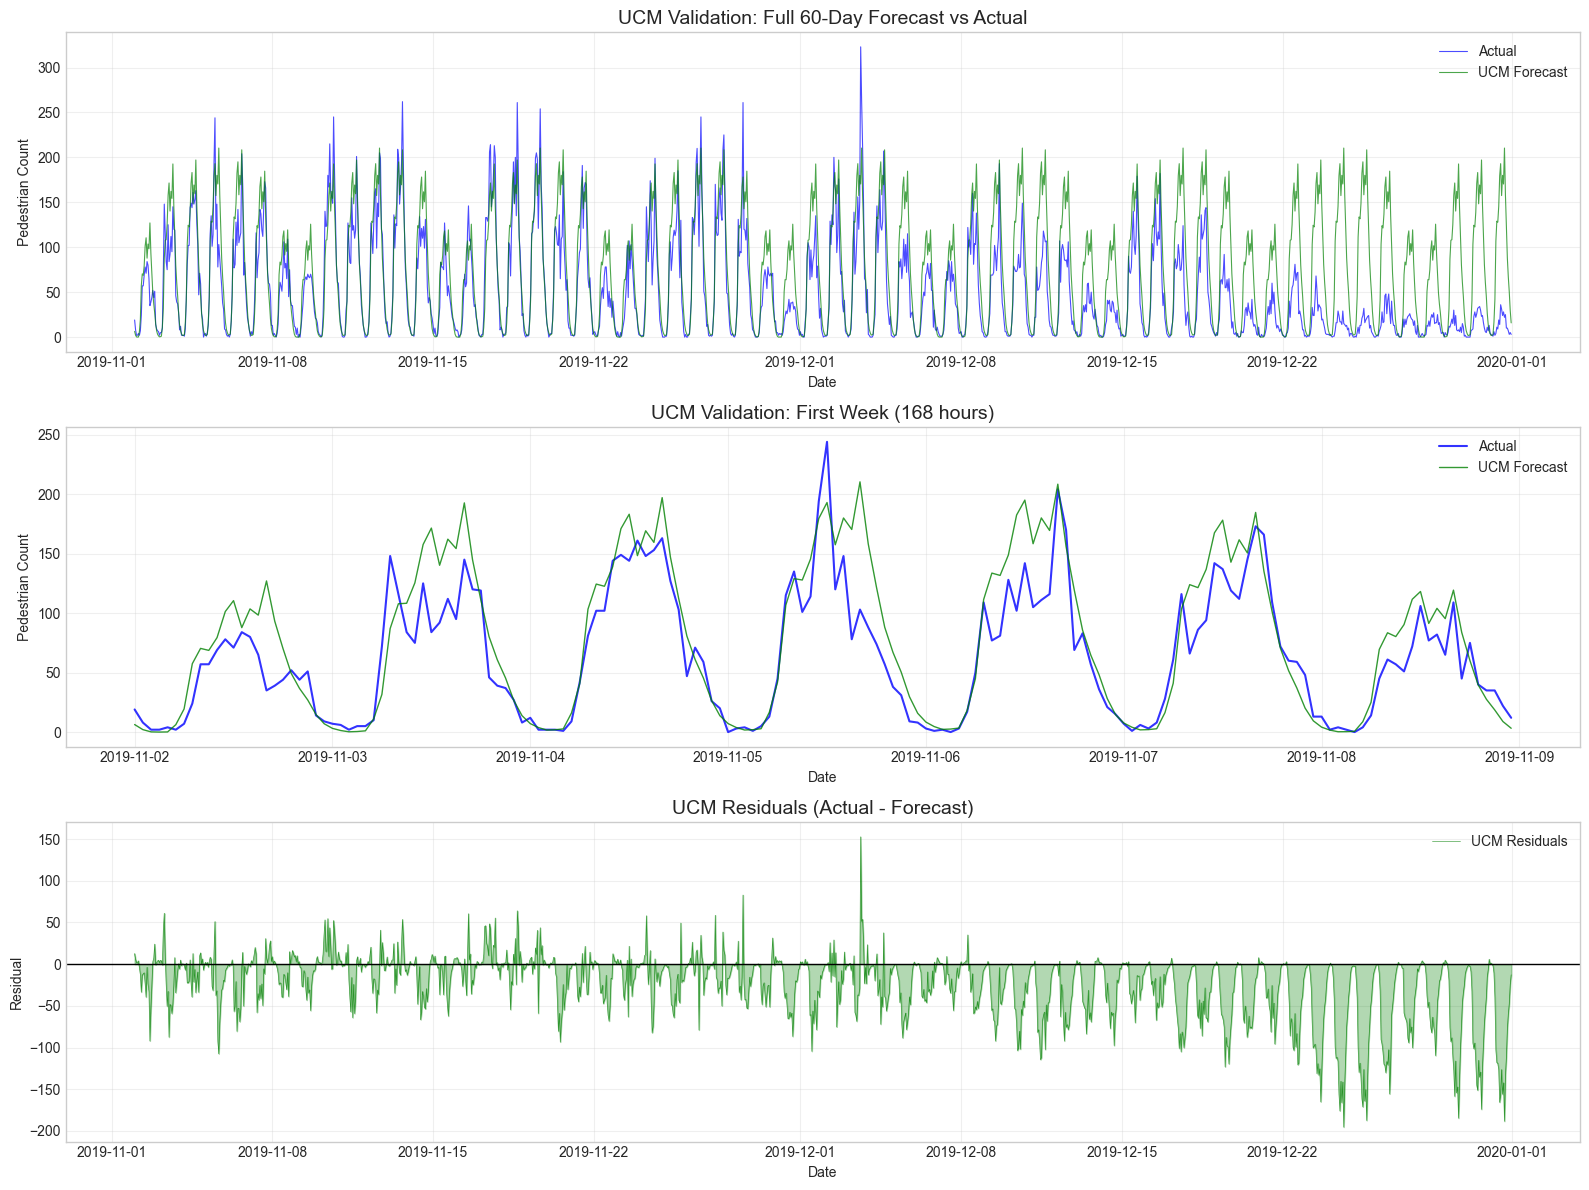

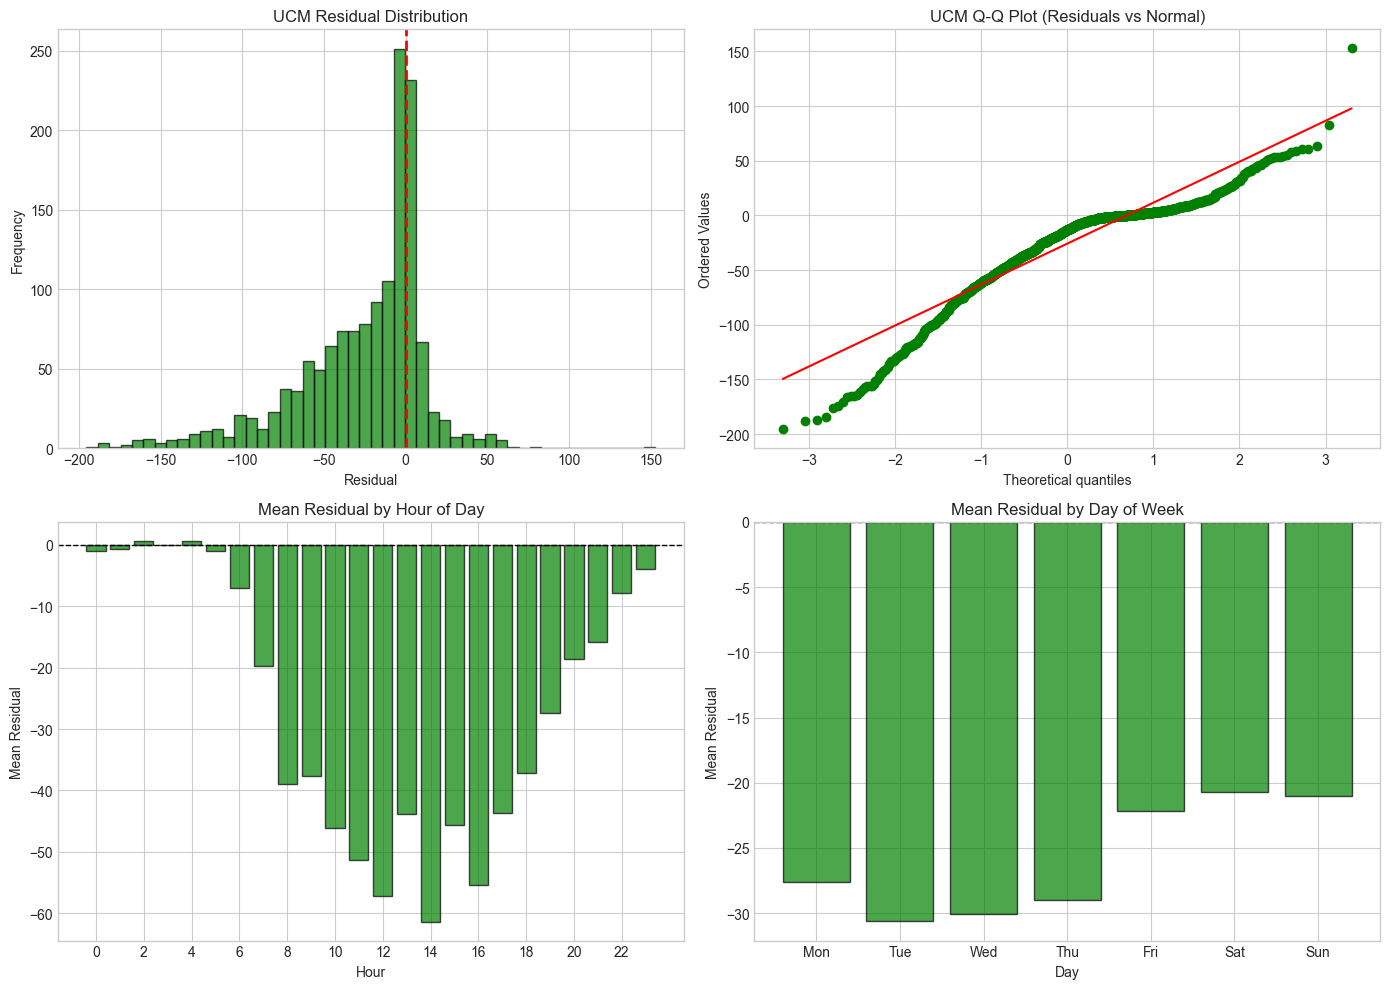

In [13]:
# =============================================================================
# UCM MODEL - PART 6: VALIDATION VISUALIZATION
# =============================================================================

fig, axes = plt.subplots(3, 1, figsize=(16, 12))

# Plot 1: Full validation forecast vs actual
ax1 = axes[0]
ax1.plot(ucm_val_forecast_df.index, ucm_val_forecast_df['actual'], 
         label='Actual', alpha=0.7, linewidth=0.8, color='blue')
ax1.plot(ucm_val_forecast_df.index, ucm_val_forecast_df['forecast'], 
         label='UCM Forecast', alpha=0.7, linewidth=0.8, color='green')
ax1.set_title('UCM Validation: Full 60-Day Forecast vs Actual', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Pedestrian Count')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: First week zoom
first_week_ucm = ucm_val_forecast_df.iloc[:168]
ax2 = axes[1]
ax2.plot(first_week_ucm.index, first_week_ucm['actual'], 
         label='Actual', alpha=0.8, linewidth=1.5, color='blue')
ax2.plot(first_week_ucm.index, first_week_ucm['forecast'], 
         label='UCM Forecast', alpha=0.8, linewidth=1, color='green')
ax2.set_title('UCM Validation: First Week (168 hours)', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Pedestrian Count')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Residuals
residuals_ucm = ucm_val_forecast_df['actual'] - ucm_val_forecast_df['forecast']
ax3 = axes[2]
ax3.plot(ucm_val_forecast_df.index, residuals_ucm, alpha=0.7, 
         linewidth=0.5, color='green', label='UCM Residuals')
ax3.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax3.fill_between(ucm_val_forecast_df.index, residuals_ucm, 0, alpha=0.3, color='green')
ax3.set_title('UCM Residuals (Actual - Forecast)', fontsize=14)
ax3.set_xlabel('Date')
ax3.set_ylabel('Residual')
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Residual diagnostics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# UCM Residual histogram
ax1 = axes[0, 0]
ax1.hist(residuals_ucm, bins=50, edgecolor='black', alpha=0.7, color='green')
ax1.axvline(x=0, color='red', linestyle='--', linewidth=2)
ax1.set_title('UCM Residual Distribution')
ax1.set_xlabel('Residual')
ax1.set_ylabel('Frequency')

# UCM Residual QQ plot
from scipy import stats
ax2 = axes[0, 1]
stats.probplot(residuals_ucm, dist="norm", plot=ax2)
ax2.set_title('UCM Q-Q Plot (Residuals vs Normal)')
ax2.get_lines()[0].set_color('green')
ax2.get_lines()[1].set_color('red')

# Residuals by hour of day
ucm_val_forecast_df['hour'] = ucm_val_forecast_df.index.hour
hourly_residuals_ucm = ucm_val_forecast_df.groupby('hour').apply(
    lambda x: (x['actual'] - x['forecast']).mean()
)
ax3 = axes[1, 0]
ax3.bar(hourly_residuals_ucm.index, hourly_residuals_ucm.values, 
        color='green', alpha=0.7, edgecolor='black')
ax3.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax3.set_title('Mean Residual by Hour of Day')
ax3.set_xlabel('Hour')
ax3.set_ylabel('Mean Residual')
ax3.set_xticks(range(0, 24, 2))

# Residuals by day of week
ucm_val_forecast_df['dayofweek'] = ucm_val_forecast_df.index.dayofweek
daily_residuals_ucm = ucm_val_forecast_df.groupby('dayofweek').apply(
    lambda x: (x['actual'] - x['forecast']).mean()
)
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
ax4 = axes[1, 1]
ax4.bar(range(7), daily_residuals_ucm.values, 
        color='green', alpha=0.7, edgecolor='black')
ax4.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax4.set_title('Mean Residual by Day of Week')
ax4.set_xlabel('Day')
ax4.set_ylabel('Mean Residual')
ax4.set_xticks(range(7))
ax4.set_xticklabels(day_names)

plt.tight_layout()
plt.show()


UCM COMPONENT DECOMPOSITION


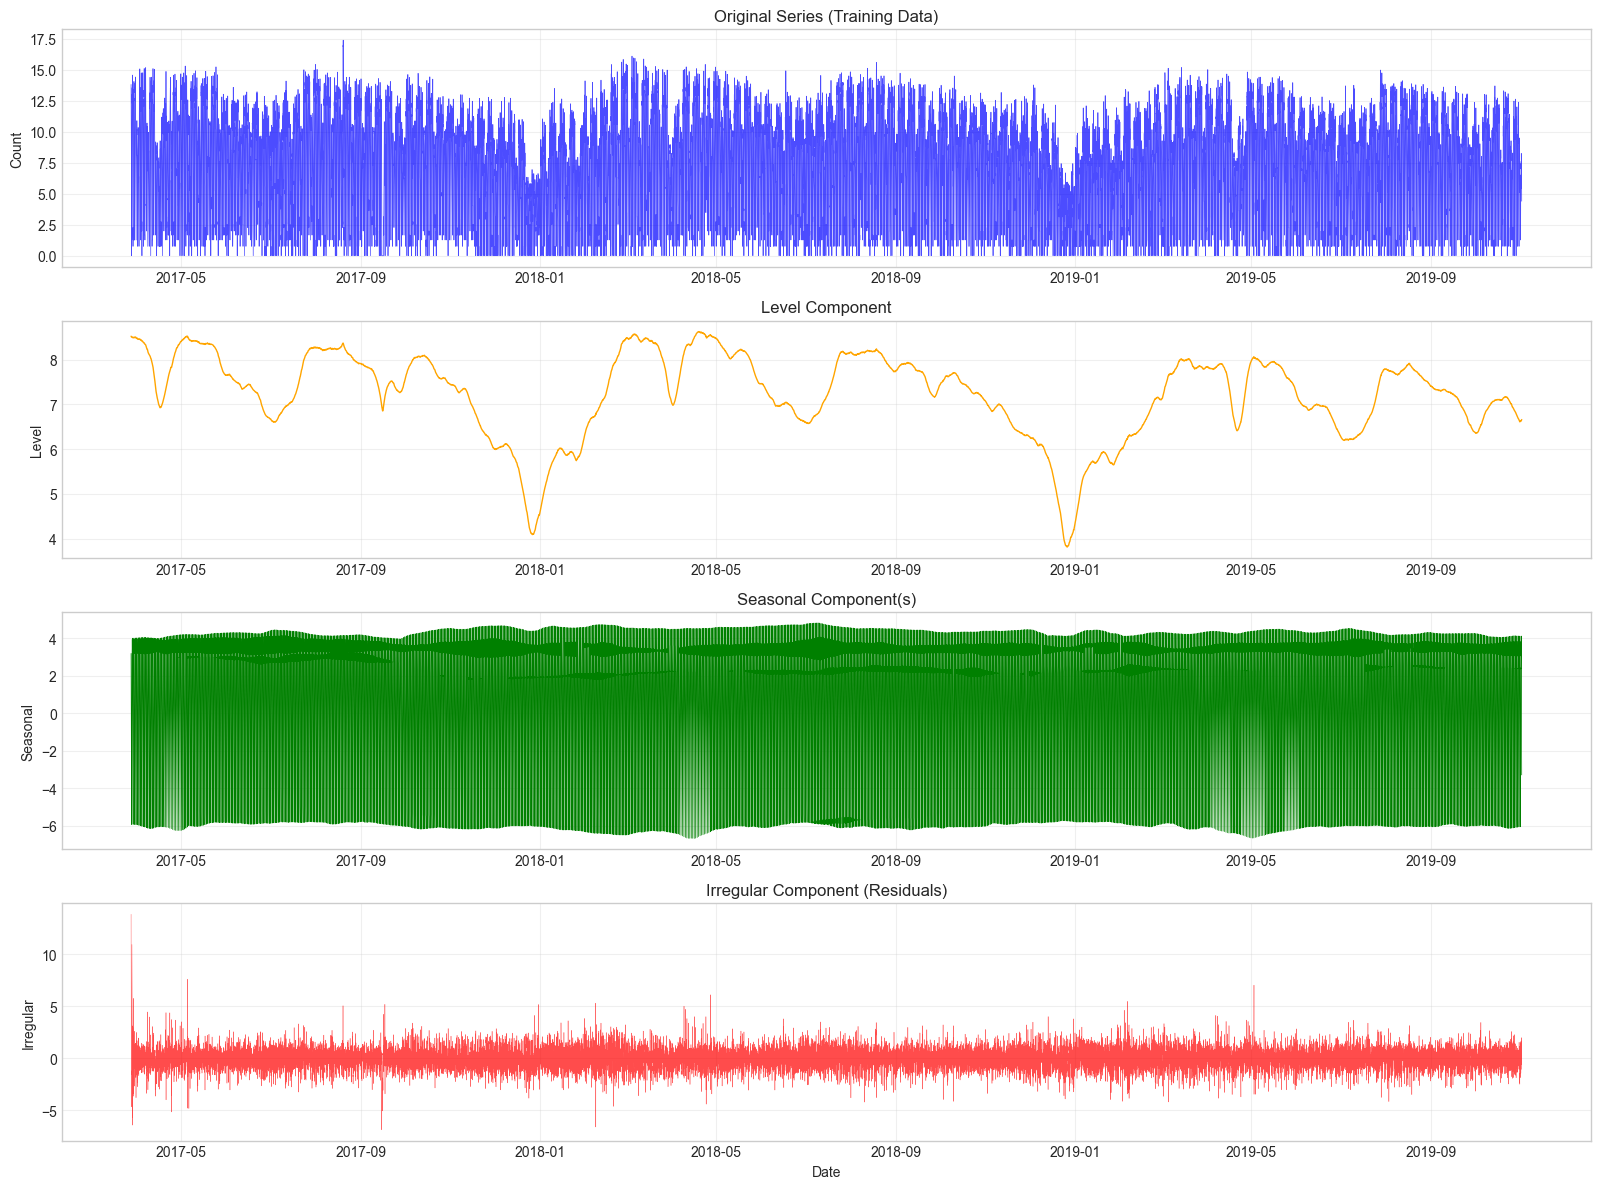


Component Statistics:
------------------------------------------------------------
Level - Mean: 7.22, Std: 0.93
Level - Range: [3.82, 8.62]

Seasonal - Mean: -0.00, Std: 3.49
Seasonal - Range: [-6.67, 4.81]

Irregular - Mean: -0.00, Std: 0.98
Irregular - Range: [-6.85, 13.82]
------------------------------------------------------------


In [14]:
# =============================================================================
# UCM MODEL - PART 7: COMPONENT DECOMPOSITION
# =============================================================================

# Extract fitted components from the best model
print("\n" + "=" * 80)
print("UCM COMPONENT DECOMPOSITION")
print("=" * 80)

# Plot components
fig, axes = plt.subplots(4, 1, figsize=(16, 12))

# Plot 1: Original series
ax1 = axes[0]
ax1.plot(train.index, y_train, alpha=0.7, linewidth=0.5, color='blue')
ax1.set_title('Original Series (Training Data)', fontsize=12)
ax1.set_ylabel('Count')
ax1.grid(True, alpha=0.3)

# Plot 2: Level component
ax2 = axes[1]
level_component = best_ucm_model.level.smoothed
ax2.plot(train.index, level_component, color='orange', linewidth=1)
ax2.set_title('Level Component', fontsize=12)
ax2.set_ylabel('Level')
ax2.grid(True, alpha=0.3)

# Plot 3: Seasonal component (if available)
ax3 = axes[2]
if hasattr(best_ucm_model, 'seasonal'):
    seasonal_component = best_ucm_model.seasonal.smoothed
    # Sum all seasonal components if multiple
    if seasonal_component.ndim > 1:
        seasonal_sum = seasonal_component.sum(axis=1)
    else:
        seasonal_sum = seasonal_component
    ax3.plot(train.index, seasonal_sum, color='green', linewidth=0.5)
    ax3.set_title('Seasonal Component(s)', fontsize=12)
else:
    ax3.text(0.5, 0.5, 'No seasonal component', ha='center', va='center', 
             transform=ax3.transAxes, fontsize=12)
ax3.set_ylabel('Seasonal')
ax3.grid(True, alpha=0.3)

# Plot 4: Irregular component
ax4 = axes[3]
irregular_component = best_ucm_model.resid  # Use .resid instead of .irregular
ax4.plot(train.index, irregular_component, color='red', linewidth=0.3, alpha=0.7)
ax4.set_title('Irregular Component (Residuals)', fontsize=12)
ax4.set_ylabel('Irregular')
ax4.set_xlabel('Date')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Show statistics of components
print("\nComponent Statistics:")
print("-" * 60)
print(f"Level - Mean: {level_component.mean():.2f}, Std: {level_component.std():.2f}")
print(f"Level - Range: [{level_component.min():.2f}, {level_component.max():.2f}]")
if hasattr(best_ucm_model, 'seasonal'):
    print(f"\nSeasonal - Mean: {seasonal_sum.mean():.2f}, Std: {seasonal_sum.std():.2f}")
    print(f"Seasonal - Range: [{seasonal_sum.min():.2f}, {seasonal_sum.max():.2f}]")
print(f"\nIrregular - Mean: {irregular_component.mean():.2f}, Std: {irregular_component.std():.2f}")
print(f"Irregular - Range: [{irregular_component.min():.2f}, {irregular_component.max():.2f}]")
print("-" * 60)

In [15]:
# =============================================================================
# UCM MODEL - PART 8: RETRAIN ON FULL DATA & FINAL FORECAST
# =============================================================================

print("\n" + "=" * 80)
print("RETRAINING UCM ON FULL DATA")
print("=" * 80)

# Combine train and validation
y_full = pd.concat([train, validation])['value']

# APPLY BOX-COX IF IT WAS USED BEFORE
if 'lam' in locals() and 'offset' in locals():
    print(f"Applying Box-Cox to full dataset with lambda={lam:.4f}")
    y_full_shifted = y_full + offset
    # Use the same lambda as found in training for consistency
    y_full_transformed = boxcox(y_full_shifted, lmbda=lam)
    y_full = pd.Series(y_full_transformed, index=y_full.index)

print(f"Full training data: {len(y_full)} observations")
print(f"Date range: {y_full.index.min()} to {y_full.index.max()}")

# Use the best specification found
best_spec = best_ucm['spec']

# Fit final UCM model
print(f"\nFitting {best_ucm_name} on full data...")
final_ucm_model = UnobservedComponents(
    y_full,
    level=best_spec['level'],
    trend=best_spec['trend'],
    seasonal=best_spec['seasonal'],
    freq_seasonal=best_spec['freq_seasonal'],
    cycle=best_spec['cycle'],
    autoregressive=best_spec['autoregressive'],
    irregular=best_spec['irregular']
)

final_ucm_fit = final_ucm_model.fit(disp=False, maxiter=200)

print("✓ Model fitted successfully")
print(f"\nFinal Model Summary:")
print(f"  AIC: {final_ucm_fit.aic:,.2f}")
print(f"  BIC: {final_ucm_fit.bic:,.2f}")
print(f"  Log Likelihood: {final_ucm_fit.llf:,.2f}")

# Generate forecast for test period
print(f"\nGenerating {FORECAST_HORIZON}-hour forecast for test period...")

try:
    # Get prediction results with standard errors
    forecast_result = final_ucm_fit.get_forecast(steps=FORECAST_HORIZON)
    ucm_forecast_mean = forecast_result.predicted_mean
    ucm_forecast_ci = forecast_result.conf_int(alpha=0.05)
    
    # INVERSE BOX-COX TRANSFORM IF APPLIED
    if 'lam' in locals() and 'offset' in locals():
        print(f"Inverse transforming final forecast using lambda={lam:.4f}")
        ucm_forecast_mean = inverse_boxcox(ucm_forecast_mean, lam, offset)
        ucm_forecast_ci = inverse_boxcox(ucm_forecast_ci, lam, offset)
    
    has_ci = True
    print("✓ Forecast with 95% confidence intervals generated")
except:
    # Fallback if confidence intervals not available
    ucm_forecast_mean = final_ucm_fit.forecast(steps=FORECAST_HORIZON)
    
    # INVERSE BOX-COX TRANSFORM IF APPLIED
    if 'lam' in locals() and 'offset' in locals():
        print(f"Inverse transforming final forecast using lambda={lam:.4f}")
        ucm_forecast_mean = inverse_boxcox(ucm_forecast_mean, lam, offset)
        
    has_ci = False
    print("✓ Forecast generated (confidence intervals not available for this specification)")

# Create future dates
# Depending on transformation, y_full might be transformed, so index is preserved
last_date = y_full.index.max()
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(hours=1),
    periods=FORECAST_HORIZON,
    freq='H'
)

print(f"\nForecast period: {future_dates.min()} to {future_dates.max()}")

# Create forecast DataFrame
if has_ci:
    ucm_final_forecast_df = pd.DataFrame({
        'date': future_dates,
        'forecast': ucm_forecast_mean.values,
        'lower_ci': ucm_forecast_ci.iloc[:, 0].values,
        'upper_ci': ucm_forecast_ci.iloc[:, 1].values
    }).set_index('date')
else:
    ucm_final_forecast_df = pd.DataFrame({
        'date': future_dates,
        'forecast': ucm_forecast_mean.values
    }).set_index('date')

# Clip negative forecasts to 0
ucm_final_forecast_df['forecast'] = ucm_final_forecast_df['forecast'].clip(lower=0)
if has_ci:
    ucm_final_forecast_df['lower_ci'] = ucm_final_forecast_df['lower_ci'].clip(lower=0)
    ucm_final_forecast_df['upper_ci'] = ucm_final_forecast_df['upper_ci'].clip(lower=0)

print("\nForecast Summary Statistics:")
print(ucm_final_forecast_df.describe())


RETRAINING UCM ON FULL DATA
Applying Box-Cox to full dataset with lambda=0.2567
Full training data: 24222 observations
Date range: 2017-03-27 18:00:01 to 2019-12-31 23:00:01

Fitting UCM-3: Local Level + Seasonal(24h) + AR(1) on full data...
✓ Model fitted successfully

Final Model Summary:
  AIC: 66,578.84
  BIC: 66,627.40
  Log Likelihood: -33,283.42

Generating 1440-hour forecast for test period...
Inverse transforming final forecast using lambda=0.2567
✓ Forecast with 95% confidence intervals generated

Forecast period: 2020-01-01 00:00:01 to 2020-02-29 23:00:01

Forecast Summary Statistics:
          forecast     lower_ci     upper_ci
count  1431.000000  1121.000000  1440.000000
mean     21.178671     4.500782    74.174396
std      21.142556     5.045268    62.215872
min       0.000000     0.000000     0.000000
25%       0.338079     0.000000    12.104364
50%      15.757457     2.616602    66.734656
75%      36.922132     7.932958   126.409675
max      64.443687    21.163216   21

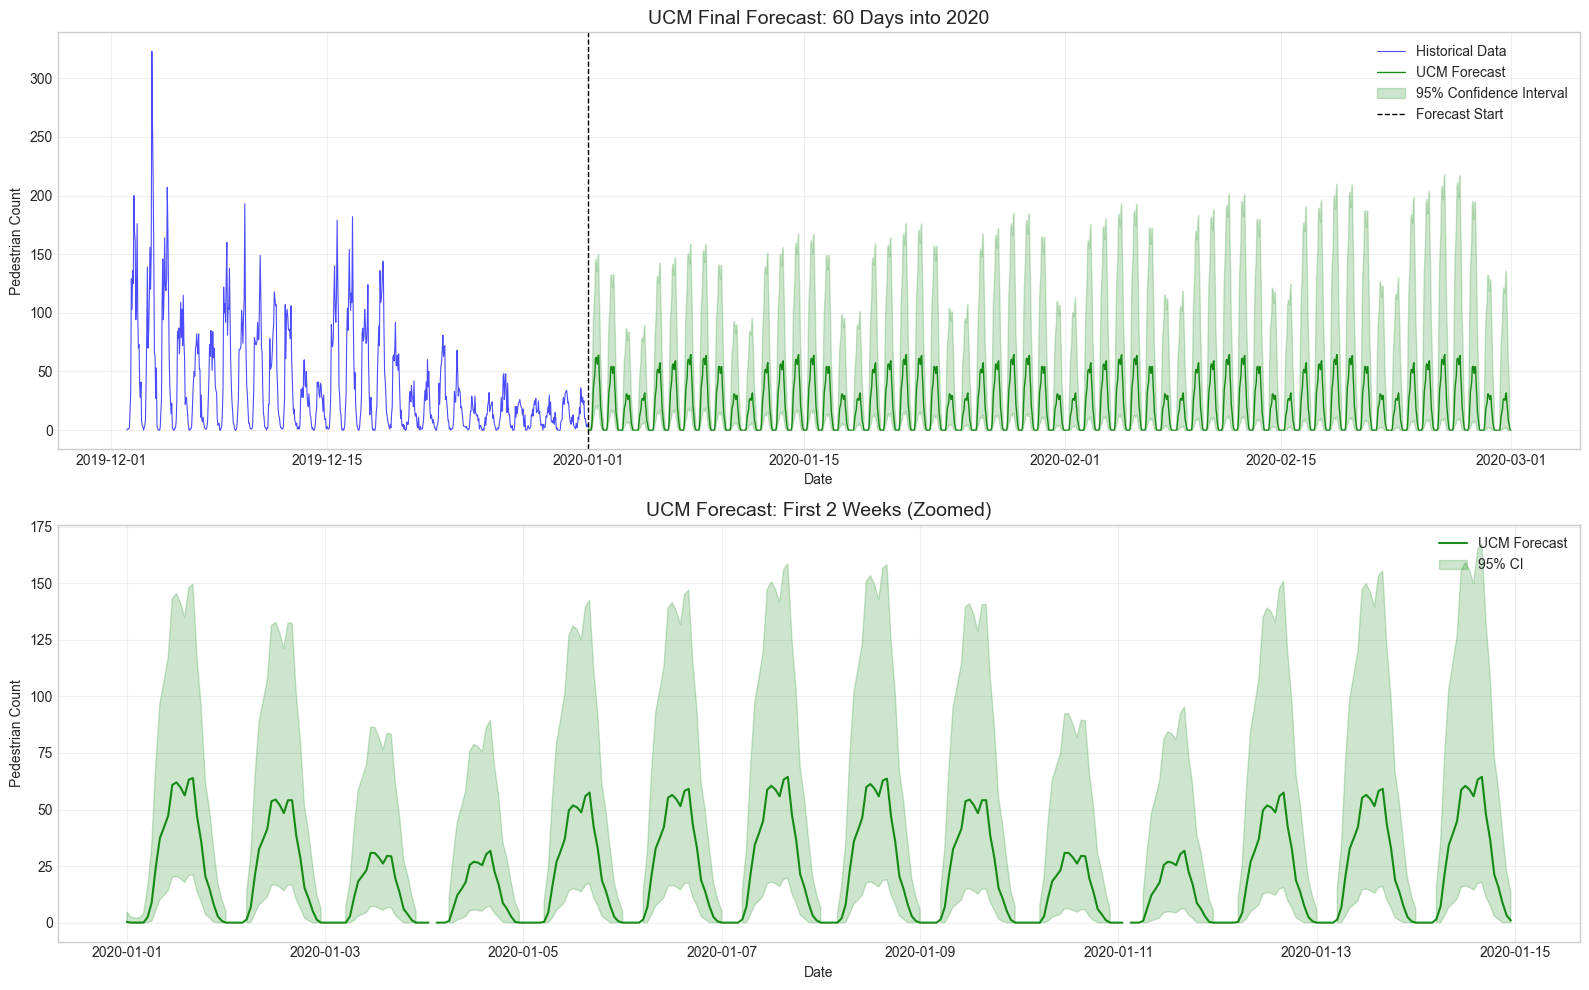

In [17]:
# =============================================================================
# UCM MODEL - PART 9: FINAL FORECAST VISUALIZATION
# =============================================================================

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Plot 1: Historical data + UCM Forecast
ax1 = axes[0]

# Last 30 days of training data for context
# Use original values for visualization (inverse transform if needed)
context_data = y_full.iloc[-720:].copy()

if 'lam' in locals() and 'offset' in locals():
    # If variables exist, y_full is likely transformed, so we inverse transform for plotting
    context_values = inverse_boxcox(context_data.values, lam, offset)
    context_data = pd.Series(context_values, index=context_data.index)

ax1.plot(context_data.index, context_data.values, 
         label='Historical Data', alpha=0.7, linewidth=0.8, color='blue')
ax1.plot(ucm_final_forecast_df.index, ucm_final_forecast_df['forecast'], 
         label='UCM Forecast', alpha=0.9, linewidth=1, color='green')

if has_ci:
    ax1.fill_between(ucm_final_forecast_df.index, 
                      ucm_final_forecast_df['lower_ci'], 
                      ucm_final_forecast_df['upper_ci'],
                      alpha=0.2, color='green', label='95% Confidence Interval')

ax1.axvline(x=y_full.index.max(), color='black', linestyle='--', 
            linewidth=1, label='Forecast Start')
ax1.set_title('UCM Final Forecast: 60 Days into 2020', fontsize=14)
ax1.set_xlabel('Date')
ax1.set_ylabel('Pedestrian Count')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Plot 2: First 2 weeks of forecast (zoomed)
first_two_weeks_ucm = ucm_final_forecast_df.iloc[:336]
ax2 = axes[1]
ax2.plot(first_two_weeks_ucm.index, first_two_weeks_ucm['forecast'], 
         label='UCM Forecast', alpha=0.9, linewidth=1.5, color='green')

if has_ci:
    ax2.fill_between(first_two_weeks_ucm.index, 
                      first_two_weeks_ucm['lower_ci'], 
                      first_two_weeks_ucm['upper_ci'],
                      alpha=0.2, color='green', label='95% CI')

ax2.set_title('UCM Forecast: First 2 Weeks (Zoomed)', fontsize=14)
ax2.set_xlabel('Date')
ax2.set_ylabel('Pedestrian Count')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()